# Análise integrada de HIV/AIDS, sífilis e indicadores demográficos — São Paulo (2019–2023)

**Notebook de análise reprodutível, com etapas comentadas, resultados e gráficos exportáveis.**

**Questão de análise:** como se distribuem as taxas municipais de HIV/AIDS e sífilis e como se associam à densidade demográfica e à proporção de área urbanizada ao longo de 2019–2023?

**Unidade de observação:** município–ano; os arquivos fornecidos contêm 645 municípios paulistas para 5 anos.

**Atenção às definições:**
- `HIV/AIDS` e `sífilis`: **taxa por 100.000 habitantes**. Os nomes das planilhas indicam 10.000, mas a reconstrução dos casos (Parte II, Etapa 16) mostra que a escala é de 100.000. Não se presume que seja incidência, prevalência ou outra definição epidemiológica específica sem conhecer a documentação de origem.
- `Densidade demográfica`: **habitantes por km²**.
- `Urbanização`: **km² de área urbanizada / km² totais do município**. É uma proporção territorial; **não** é o percentual de habitantes em área urbana.

> **Aviso metodológico:** a análise é municipal/ecológica e observacional. Associações e regressões não demonstram causalidade. Médias municipais têm *peso igual por município*, não equivalendo a taxas populacionais agregadas do estado. Taxas muito elevadas de municípios pequenos merecem interpretação prudente, pois não há nesta base os numeradores e denominadores que permitiriam avaliar sua estabilidade.

> **Notas de revisão:** (1) unidade das taxas corrigida para **por 100 mil habitantes**; (2) o ano de referência das análises transversais (Gráficos 5 a 7) passou de 2023 para **2022**, porque os valores de 2023 repetem os de 2022 (integralmente para sífilis, parcialmente para HIV/AIDS) — ver Parte II, Etapa 17; (3) a Parte I usa as planilhas como fornecidas, sem a correção capital/São Miguel Arcanjo aplicada na Parte II.

## Etapa 1 — Bibliotecas, aparência e caminhos

**O que será feito:** importar as bibliotecas, definir a pasta de resultados e localizar os quatro arquivos. As figuras terão título, identificação dos eixos e nota explicativa. Os códigos funcionam no Jupyter ou no Google Colab; no Colab, basta enviar os quatro `.xlsx` caso não estejam presentes.

**Bibliotecas utilizadas:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `statsmodels` e `openpyxl` (leitura do Excel). Se necessário, instale-as com `!pip install pandas numpy matplotlib seaborn scipy statsmodels openpyxl`.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.02)
plt.rcParams.update({"figure.dpi": 115, "savefig.dpi": 170, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 130)

PASTA_PROJETO = Path.cwd()
PASTA_RESULTADOS = PASTA_PROJETO / "resultados"
PASTA_FIGURAS = PASTA_RESULTADOS / "graficos"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

ARQUIVOS = {
    "hiv_aids": "AIDS_HIV.xlsx",
    "sifilis": "Sifilis.xlsx",
    "densidade": "Densidade demografica.xlsx",
    "urbanizacao": "Indice de urbanizacao.xlsx",
}
ANOS = [2019, 2020, 2021, 2022, 2023]
ANO_REFERENCIA = 2022   # 2023 repete 2022 (ver Parte II); usado nas análises de um único ano
UNIDADES = {
    "hiv_aids": "por 100.000 habitantes",
    "sifilis": "por 100.000 habitantes",
    "densidade": "habitantes/km²",
    "urbanizacao": "fração da área municipal",
}


def localizar_arquivo(nome):
    for pasta in (PASTA_PROJETO / "dados", PASTA_PROJETO, Path("/mnt/data"), Path("/content")):
        caminho = pasta / nome
        if caminho.is_file():
            return caminho
    return None

faltando = [nome for nome in ARQUIVOS.values() if localizar_arquivo(nome) is None]
if faltando:
    try:
        from google.colab import files  # utilizado apenas quando executado no Colab
        print("Envie os arquivos ausentes:", ", ".join(faltando))
        files.upload()
    except ImportError:
        pass

CAMINHOS = {chave: localizar_arquivo(nome) for chave, nome in ARQUIVOS.items()}
if any(caminho is None for caminho in CAMINHOS.values()):
    raise FileNotFoundError("Arquivos não encontrados: " + ", ".join(
        ARQUIVOS[chave] for chave, caminho in CAMINHOS.items() if caminho is None
    ))

print("Pasta de trabalho:", PASTA_PROJETO)
print("Pasta dos resultados:", PASTA_RESULTADOS)
for chave, caminho in CAMINHOS.items():
    print(f"  {chave:12s} ← {caminho.name}")


def salvar_figura(nome):
    """Salva figura e a exibe no notebook."""
    plt.savefig(PASTA_FIGURAS / nome, bbox_inches="tight", facecolor="white")
    plt.show()


def salvar_tabela(tabela, nome):
    """Exporta CSV com separador e vírgula decimal próprios para Excel brasileiro."""
    tabela.to_csv(PASTA_RESULTADOS / nome, sep=";", decimal=",", index=False, encoding="utf-8-sig")

Pasta de trabalho: /home/claude/nb
Pasta dos resultados: /home/claude/nb/resultados
  hiv_aids     ← AIDS_HIV.xlsx
  sifilis      ← Sifilis.xlsx
  densidade    ← Densidade demografica.xlsx
  urbanizacao  ← Indice de urbanizacao.xlsx


## Etapa 2 — Leitura, padronização e validação

**O que será feito:** ler todas as abas, converter o formato largo (uma coluna por ano) para o formato longo (uma linha por município e ano), e juntar as quatro fontes pela chave única `CD_MUN` + `ano`.

**Por que usar `CD_MUN` em vez do nome?** A grafia dos nomes difere entre os arquivos (por exemplo, acentuação e maiúsculas); o código municipal evita correspondências incorretas.

**Verificações:** unicidade por município–ano, cobertura de anos, ausência de valores negativos e faixa válida para o indicador de urbanização.

In [2]:
def ler_indicador(nome_variavel, caminho):
    bruto = pd.read_excel(caminho, sheet_name=0, engine="openpyxl")
    bruto.columns = [str(col).strip() for col in bruto.columns]
    obrigatorias = {"MUN", "CD_MUN", *map(str, ANOS)}
    ausentes = obrigatorias.difference(bruto.columns)
    if ausentes:
        raise ValueError(f"{caminho.name}: colunas obrigatórias ausentes: {sorted(ausentes)}")

    bruto["CD_MUN"] = pd.to_numeric(bruto["CD_MUN"], errors="raise").astype("Int64").astype(str).str.zfill(7)
    if not bruto["CD_MUN"].str.fullmatch(r"\d{7}").all():
        raise ValueError(f"Código municipal inválido em {caminho.name}")
    if bruto["CD_MUN"].duplicated().any():
        raise ValueError(f"Códigos municipais duplicados em {caminho.name}")

    longo = bruto.melt(
        id_vars=["MUN", "CD_MUN"], value_vars=list(map(str, ANOS)),
        var_name="ano", value_name=nome_variavel,
    )
    longo["ano"] = longo["ano"].astype(int)
    longo[nome_variavel] = pd.to_numeric(longo[nome_variavel], errors="coerce")
    if (longo[nome_variavel].dropna() < 0).any():
        warnings.warn(f"Há valores negativos em {nome_variavel}; verificar a origem.")
    if nome_variavel == "urbanizacao" and (~longo[nome_variavel].dropna().between(0, 1)).any():
        warnings.warn("Urbanização contém valores fora da fração [0, 1].")

    if nome_variavel == "hiv_aids":
        return longo.rename(columns={"MUN": "municipio"})
    return longo.drop(columns=["MUN"])


fontes = {chave: ler_indicador(chave, caminho) for chave, caminho in CAMINHOS.items()}
codigos_base = set(fontes["hiv_aids"]["CD_MUN"].unique())
for chave, tabela in fontes.items():
    codigos = set(tabela["CD_MUN"].unique())
    print(f"{chave:12s}: {len(codigos)} municípios, {len(tabela)} linhas, "
          f"{tabela[chave].isna().sum()} valores ausentes")
    if codigos != codigos_base:
        warnings.warn(f"Conjunto de municípios de {chave} diferente da base HIV/AIDS.")

dados = fontes["hiv_aids"].copy()
for chave in ("sifilis", "densidade", "urbanizacao"):
    dados = dados.merge(fontes[chave], on=["CD_MUN", "ano"], how="inner", validate="one_to_one")

dados = dados.sort_values(["ano", "municipio"]).reset_index(drop=True)
assert not dados.duplicated(["CD_MUN", "ano"]).any(), "Existem chaves município–ano repetidas."
print(f"\nBASE INTEGRADA: {len(dados)} registros, {dados.CD_MUN.nunique()} municípios, "
      f"anos {dados.ano.min()}–{dados.ano.max()}")
display(dados.head(8))
salvar_tabela(dados, "base_municipio_ano.csv")

hiv_aids    : 645 municípios, 3225 linhas, 0 valores ausentes
sifilis     : 645 municípios, 3225 linhas, 0 valores ausentes
densidade   : 645 municípios, 3225 linhas, 0 valores ausentes
urbanizacao : 645 municípios, 3225 linhas, 0 valores ausentes

BASE INTEGRADA: 3225 registros, 645 municípios, anos 2019–2023


,municipio,CD_MUN,ano,hiv_aids,sifilis,densidade,urbanizacao
0,Adamantina,3500105,2019,5.703205,11.406410,85.119289,0.026313
1,Adolfo,3500204,2019,0.000000,0.000000,16.877103,0.006857
2,Aguaí,3500303,2019,5.508883,0.000000,76.503488,0.017442
3,Agudos,3500709,2019,2.687161,0.000000,38.495596,0.010792
4,Alambari,3500758,2019,0.000000,0.000000,37.750539,0.017325
5,Alfredo Marcondes,3500808,2019,0.000000,0.000000,35.033343,0.007838
6,Altair,3500907,2019,0.000000,24.038462,13.290455,0.002347
7,Altinópolis,3501004,2019,0.000000,0.000000,17.421701,0.004152


## Etapa 3 — Qualidade dos dados e dicionário de variáveis

**O que será feito:** quantificar valores ausentes, zeros, amplitudes e números de observações. **Interpretação:** taxa igual a zero pode representar ausência de registros, enquanto valores ausentes indicariam informação não disponibilizada; eles não serão confundidos.

**Regra:** não removeremos taxas altas automaticamente, pois não há fundamento documental para classificá-las como erros.

In [3]:
linhas_qualidade = []
for variavel in ARQUIVOS:
    valores = dados[variavel]
    linhas_qualidade.append({
        "variavel": variavel,
        "unidade": UNIDADES[variavel],
        "observacoes": len(valores),
        "faltantes": int(valores.isna().sum()),
        "zeros": int((valores == 0).sum()),
        "pct_zeros": round(100 * (valores == 0).mean(), 2),
        "minimo": valores.min(),
        "maximo": valores.max(),
        "negativos": int((valores < 0).sum()),
    })
qualidade = pd.DataFrame(linhas_qualidade)
display(qualidade.round(3))
salvar_tabela(qualidade, "qualidade_dos_dados.csv")

if dados[list(ARQUIVOS)].isna().any().any():
    print("AVISO: existem dados ausentes; os testes usarão pares completos.")
else:
    print("Não foram identificados valores ausentes nas quatro variáveis.")
print("Não confundir: urbanização mede proporção de ÁREA urbanizada, não população urbana.")

,variavel,unidade,observacoes,faltantes,zeros,pct_zeros,minimo,maximo,negativos
0,hiv_aids,por 100.000 habitantes,3225,0,1836,56.93,0.000,713.758,0
1,sifilis,por 100.000 habitantes,3225,0,1803,55.91,0.000,100.334,0
2,densidade,habitantes/km²,3225,0,0,0.00,3.512,14593.451,0
3,urbanizacao,fração da área municipal,3225,0,0,0.00,0.000,0.999,0


Não foram identificados valores ausentes nas quatro variáveis.
Não confundir: urbanização mede proporção de ÁREA urbanizada, não população urbana.


## Etapa 4 — Estatística descritiva por ano

**O que será feito:** calcular média, mediana, desvio-padrão, quartis (25% e 75%), mínimo, máximo e proporção de municípios com zero.

**Interpretação:** a *média não ponderada* descreve o município típico de um conjunto com igual peso entre municípios. A mediana e os quartis são particularmente importantes por causa de muitos valores zero e observações extremas. Não calcular uma “taxa estadual” somando ou fazendo a média dessas taxas sem denominadores populacionais.

In [4]:
rotulos = {
    "hiv_aids": "HIV/AIDS",
    "sifilis": "Sífilis",
    "densidade": "Densidade demográfica",
    "urbanizacao": "Fração de área urbanizada",
}

resumos = []
for variavel in ARQUIVOS:
    for ano, grupo in dados.groupby("ano", sort=True):
        serie = grupo[variavel].dropna()
        resumos.append({
            "indicador": rotulos[variavel], "variavel": variavel, "ano": int(ano),
            "n": len(serie), "media": serie.mean(), "mediana": serie.median(),
            "desvio_padrao": serie.std(), "q25": serie.quantile(0.25),
            "q75": serie.quantile(0.75), "minimo": serie.min(),
            "maximo": serie.max(), "pct_zeros": 100 * (serie == 0).mean(),
        })
resumo_anual = pd.DataFrame(resumos)
display(resumo_anual.round(3))
salvar_tabela(resumo_anual, "estatisticas_descritivas_anuais.csv")

resumo_taxas = resumo_anual[resumo_anual["variavel"].isin(["hiv_aids", "sifilis"])]
print("Resumo das médias anuais (taxas por 100 mil habitantes; pesos iguais por município):")
display(resumo_taxas.pivot(index="ano", columns="indicador", values="media").round(2))

,indicador,variavel,ano,n,media,mediana,desvio_padrao,q25,q75,minimo,maximo,pct_zeros
0,HIV/AIDS,hiv_aids,2019,645,16.014,0.000,58.400,0.000,8.940,0.000,630.835,56.279
1,HIV/AIDS,hiv_aids,2020,645,12.113,0.000,42.524,0.000,6.368,0.000,523.169,61.395
2,HIV/AIDS,hiv_aids,2021,645,12.448,0.000,43.624,0.000,7.161,0.000,713.758,59.070
3,HIV/AIDS,hiv_aids,2022,645,15.392,0.000,47.154,0.000,9.589,0.000,447.344,53.953
4,HIV/AIDS,hiv_aids,2023,645,6.473,0.000,14.558,0.000,7.276,0.000,146.359,53.953
5,Sífilis,sifilis,2019,645,4.747,0.000,8.759,0.000,6.091,0.000,56.338,56.434
6,Sífilis,sifilis,2020,645,4.218,0.000,7.408,0.000,5.866,0.000,51.335,57.829
7,Sífilis,sifilis,2021,645,5.319,0.000,9.590,0.000,7.866,0.000,95.465,54.574
8,Sífilis,sifilis,2022,645,4.826,0.000,8.579,0.000,7.589,0.000,100.334,55.349
9,Sífilis,sifilis,2023,645,4.865,0.000,8.586,0.000,7.828,0.000,99.174,55.349


Resumo das médias anuais (taxas por 100 mil habitantes; pesos iguais por município):


indicador,HIV/AIDS,Sífilis
ano,,
2019,16.01,4.75
2020,12.11,4.22
2021,12.45,5.32
2022,15.39,4.83
2023,6.47,4.87


## Etapa 5 — Gráfico 1: evolução anual das taxas de HIV/AIDS e sífilis

**O que será feito:** comparar as médias e medianas municipais em cada ano.

**Legenda:** linhas contínuas representam médias municipais; linhas tracejadas, medianas. **Importante:** a variação ao longo do tempo pode refletir mudanças de notificação, cobertura ou definição do indicador; não confirma por si só aumento ou queda da ocorrência real.

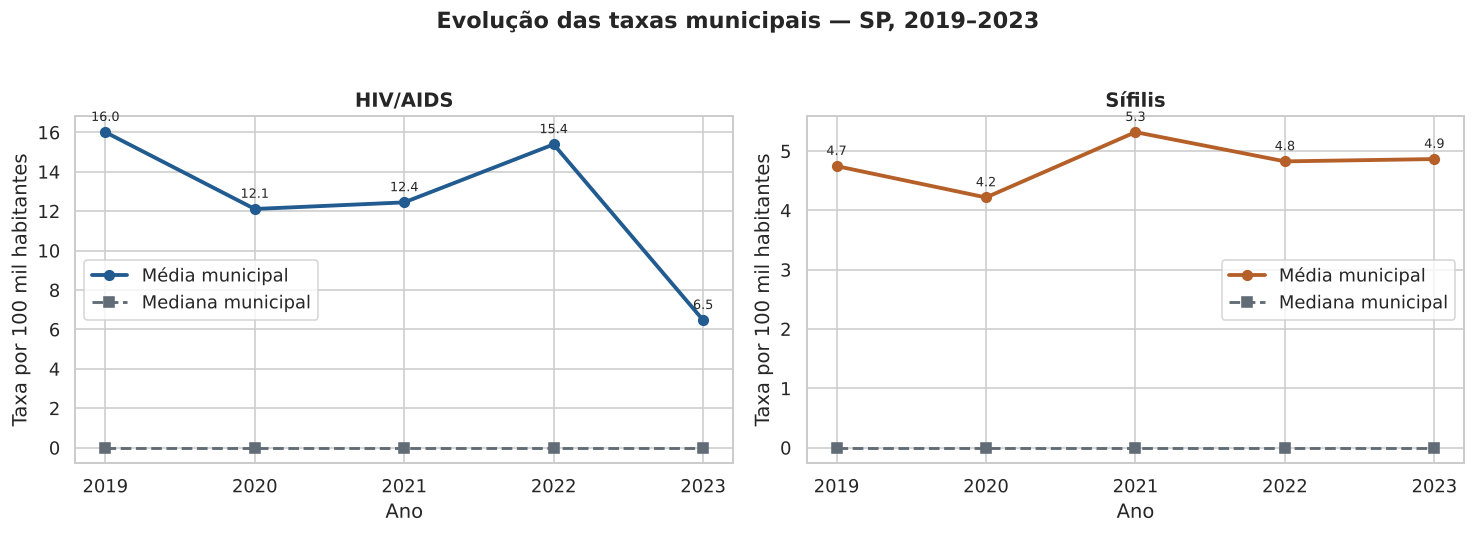

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
cores = {"hiv_aids": "#215B8F", "sifilis": "#B55F29"}
for ax, variavel in zip(eixos, ("hiv_aids", "sifilis")):
    t = resumo_anual.query("variavel == @variavel").sort_values("ano")
    ax.plot(t.ano, t.media, "o-", lw=2.4, color=cores[variavel], label="Média municipal")
    ax.plot(t.ano, t.mediana, "s--", lw=1.8, color="#616C76", label="Mediana municipal")
    ax.set(title=rotulos[variavel], xlabel="Ano", ylabel="Taxa por 100 mil habitantes")
    ax.set_xticks(ANOS)
    ax.legend(frameon=True)
    for ano, media in zip(t.ano, t.media):
        ax.annotate(f"{media:.1f}", (ano, media), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
fig.suptitle("Evolução das taxas municipais — SP, 2019–2023", y=1.03, fontsize=14, weight="bold")
fig.tight_layout()
salvar_figura("01_evolucao_anual.png")

## Etapa 6 — Gráfico 2: distribuição e valores extremos

**O que será feito:** examinar a variabilidade entre municípios usando boxplots por ano.

**Legenda:** a linha dentro da caixa é a mediana; a caixa cobre os quartis 25–75%; pontos além dos limites usuais do boxplot são observações extremas, **não necessariamente erros**. Como as distribuições têm muitos zeros e valores elevados, usamos `log(1 + taxa)` apenas na visualização. O valor original permanece intacto na base.

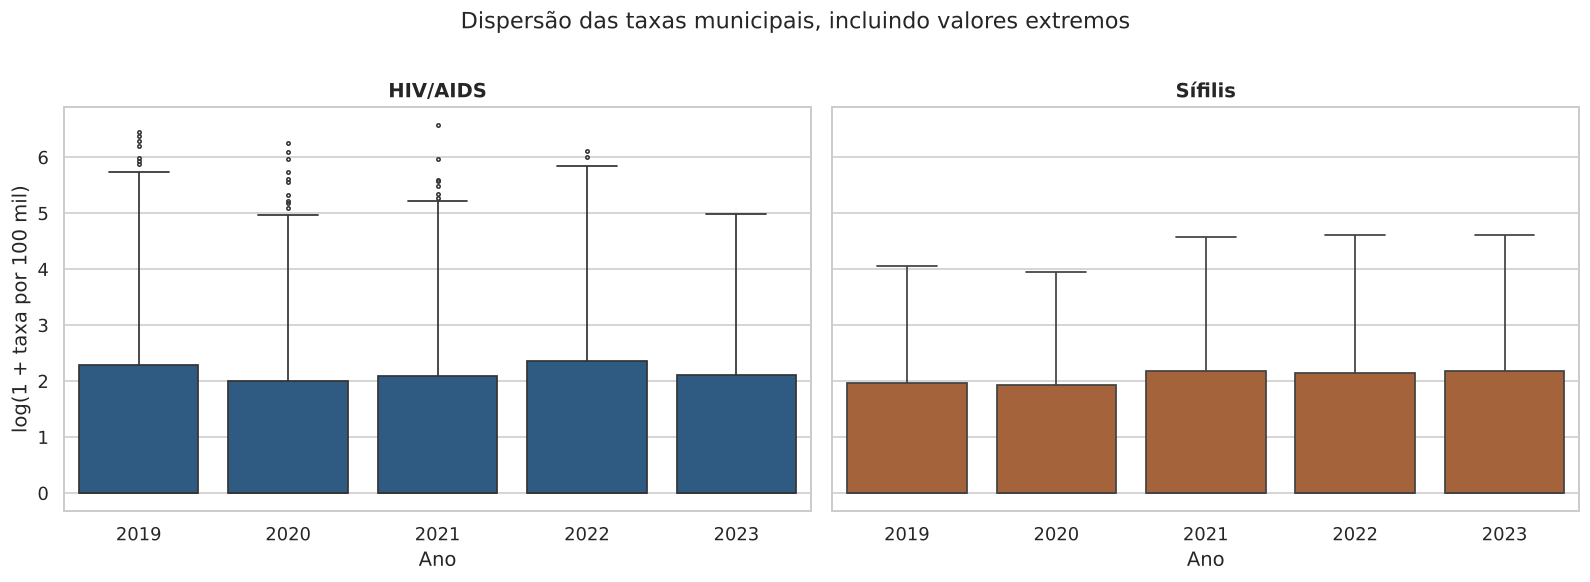

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, variavel in zip(eixos, ("hiv_aids", "sifilis")):
    t = dados[["ano", variavel]].copy()
    t["taxa_log"] = np.log1p(t[variavel])
    sns.boxplot(data=t, x="ano", y="taxa_log", color=cores[variavel],
                fliersize=2.1, linewidth=1.1, ax=ax)
    ax.set(title=rotulos[variavel], xlabel="Ano", ylabel="log(1 + taxa por 100 mil)")
fig.suptitle("Dispersão das taxas municipais, incluindo valores extremos", y=1.01, fontsize=14)
fig.tight_layout()
salvar_figura("02_distribuicao_boxplots.png")

## Etapa 7 — Gráfico 3: municípios com taxa registrada igual a zero

**O que será feito:** mostrar o percentual de municípios com valor igual a zero para cada doença em cada ano.

**Interpretação:** esse percentual é calculado sobre **municípios**, não sobre pessoas. Um zero na base pode ter significados distintos dependendo da origem e da metodologia de registro.

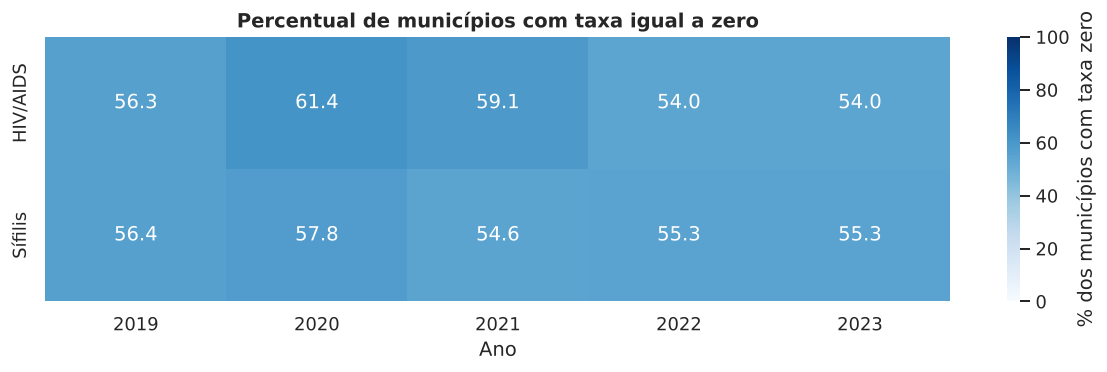

In [7]:
tabela_zeros = resumo_taxas.pivot(index="indicador", columns="ano", values="pct_zeros")
fig, ax = plt.subplots(figsize=(10.5, 3.4))
sns.heatmap(tabela_zeros, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            cbar_kws={"label": "% dos municípios com taxa zero"}, ax=ax)
ax.set(title="Percentual de municípios com taxa igual a zero", xlabel="Ano", ylabel="")
fig.tight_layout()
salvar_figura("03_percentual_zeros.png")

## Etapa 8 — Correlações de Spearman por ano (com correção para múltiplos testes)

**O que será feito:** estimar a correlação de postos de Spearman (`ρ`) entre as taxas de infecção e os indicadores demográficos, além da relação HIV/AIDS–sífilis.

**Por que Spearman?** Há muitos valores zero, assimetria e observações extremas; Spearman é uma medida de associação monotônica baseada em postos. Cada ano é analisado separadamente, sem tratar os cinco registros do mesmo município como observações independentes no teste.

**Inferência:** são feitas 25 comparações (5 pares × 5 anos). Os valores de `p` são ajustados por Benjamini–Hochberg (FDR). `ρ` próximo de +1 indica associação positiva; próximo de −1, negativa; próximo de 0, pouca associação monotônica. Significância estatística **não** equivale a relevância clínica nem a causalidade.

In [8]:
pares = [
    ("hiv_aids", "sifilis"),
    ("hiv_aids", "densidade"),
    ("hiv_aids", "urbanizacao"),
    ("sifilis", "densidade"),
    ("sifilis", "urbanizacao"),
]
resultados_corr = []
for ano, grupo in dados.groupby("ano", sort=True):
    for x, y in pares:
        pares_validos = grupo[[x, y]].dropna()
        rho, p_valor = spearmanr(pares_validos[x], pares_validos[y])
        resultados_corr.append({
            "ano": int(ano), "variavel_1": x, "variavel_2": y,
            "comparacao": f"{rotulos[x]} × {rotulos[y]}",
            "n": len(pares_validos), "rho_spearman": float(rho),
            "p_bruto": float(p_valor),
        })
correlacoes = pd.DataFrame(resultados_corr)
correlacoes["p_fdr"] = multipletests(correlacoes["p_bruto"], method="fdr_bh")[1]
correlacoes["significativo_fdr_5pct"] = correlacoes["p_fdr"] < 0.05
display(correlacoes.round({"rho_spearman": 3, "p_bruto": 5, "p_fdr": 5}))
salvar_tabela(correlacoes, "correlacoes_spearman_por_ano.csv")

,ano,variavel_1,variavel_2,comparacao,n,rho_spearman,p_bruto,p_fdr,significativo_fdr_5pct
0,2019,hiv_aids,sifilis,HIV/AIDS × Sífilis,645,0.027,0.49200,0.51250,False
1,2019,hiv_aids,densidade,HIV/AIDS × Densidade demográfica,645,0.090,0.02252,0.02681,True
2,2019,hiv_aids,urbanizacao,HIV/AIDS × Fração de área urbanizada,645,0.092,0.01908,0.02510,True
3,2019,sifilis,densidade,Sífilis × Densidade demográfica,645,0.318,0.00000,0.00000,True
4,2019,sifilis,urbanizacao,Sífilis × Fração de área urbanizada,645,0.326,0.00000,0.00000,True
5,2020,hiv_aids,sifilis,HIV/AIDS × Sífilis,645,0.077,0.05110,0.05806,False
6,2020,hiv_aids,densidade,HIV/AIDS × Densidade demográfica,645,0.098,0.01300,0.01911,True
7,2020,hiv_aids,urbanizacao,HIV/AIDS × Fração de área urbanizada,645,0.127,0.00118,0.00227,True
8,2020,sifilis,densidade,Sífilis × Densidade demográfica,645,0.449,0.00000,0.00000,True
9,2020,sifilis,urbanizacao,Sífilis × Fração de área urbanizada,645,0.431,0.00000,0.00000,True


## Etapa 9 — Gráficos 4 e 5: evolução das correlações e matriz do ano de referência (2022)

**O que será feito:** visualizar o comportamento de `ρ` por ano e a matriz completa de correlações entre as quatro variáveis no último ano disponível.

**Legenda:** cores indicam valores positivos ou negativos de Spearman; a linha pontilhada horizontal representa associação nula (`ρ = 0`). A matriz refere-se exclusivamente a 2022, evitando duplicar observações de cada município.

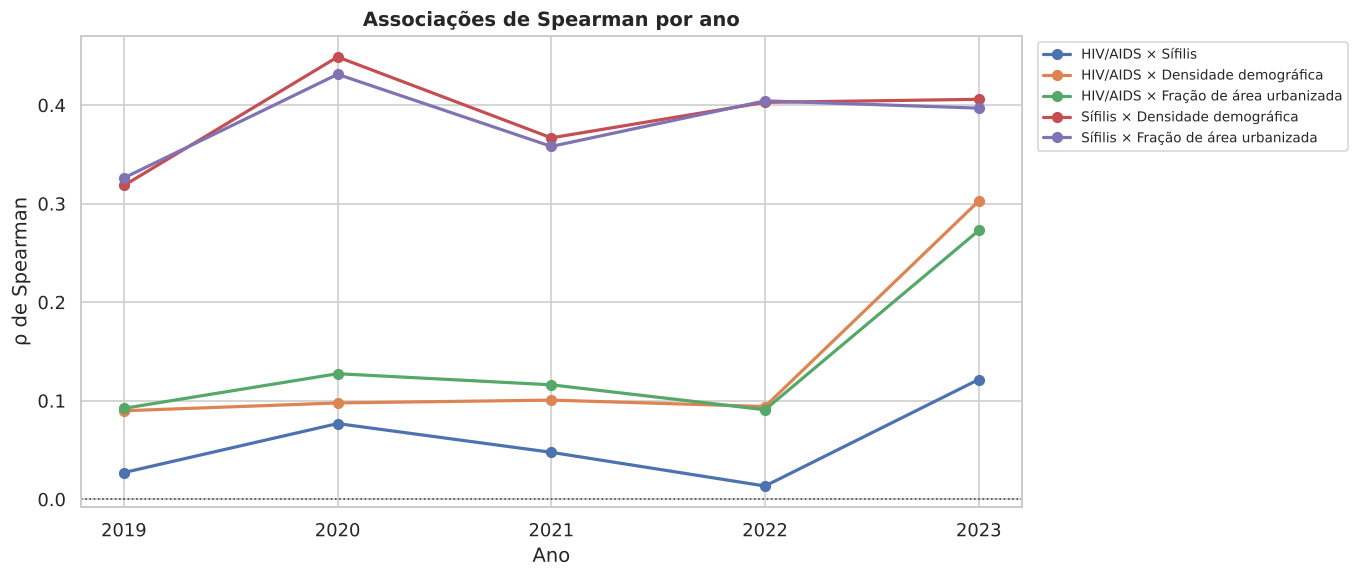

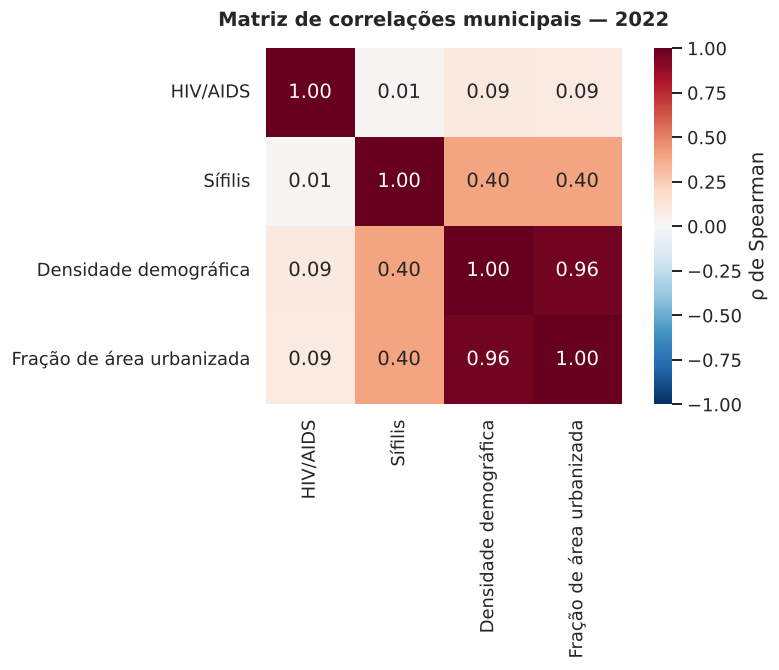

In [9]:
fig, ax = plt.subplots(figsize=(12, 5.2))
for nome, grupo in correlacoes.groupby("comparacao", sort=False):
    ax.plot(grupo.ano, grupo.rho_spearman, marker="o", lw=2, label=nome)
ax.axhline(0, color="#444444", linestyle=":", lw=1)
ax.set(title="Associações de Spearman por ano", xlabel="Ano", ylabel="ρ de Spearman", xticks=ANOS)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8.5, frameon=True)
fig.tight_layout()
salvar_figura("04_evolucao_correlacoes.png")

ultimo_ano = ANO_REFERENCIA      # 2022; 2023 não é usado por repetir 2022
dados_ref = dados[dados.ano == ultimo_ano].copy()
matriz = dados_ref[list(ARQUIVOS)].corr(method="spearman")
matriz = matriz.rename(index=rotulos, columns=rotulos)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(matriz, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"label": "ρ de Spearman"}, ax=ax)
ax.set_title(f"Matriz de correlações municipais — {ultimo_ano}", pad=14)
fig.tight_layout()
salvar_figura(f"05_matriz_correlacao_{ultimo_ano}.png")

## Etapa 10 — Gráfico 6: dispersão das taxas e indicadores territoriais no ano de referência (2022)

**O que será feito:** produzir quatro diagramas de dispersão (duas doenças × dois indicadores territoriais), com linha de tendência local (`LOWESS`, apenas descritiva).

**Escalas:** usamos `log(1 + densidade)` e `log(1 + taxa)` para facilitar a visualização; a urbanização é convertida para **percentual da área do município** (`fração × 100`). Os valores não são substituídos na análise de Spearman.

**Legenda:** cada ponto representa um município; a linha suavizada descreve a forma da relação, não um efeito causal. O coeficiente `ρ` apresentado em cada painel é o de Spearman calculado para 2022.

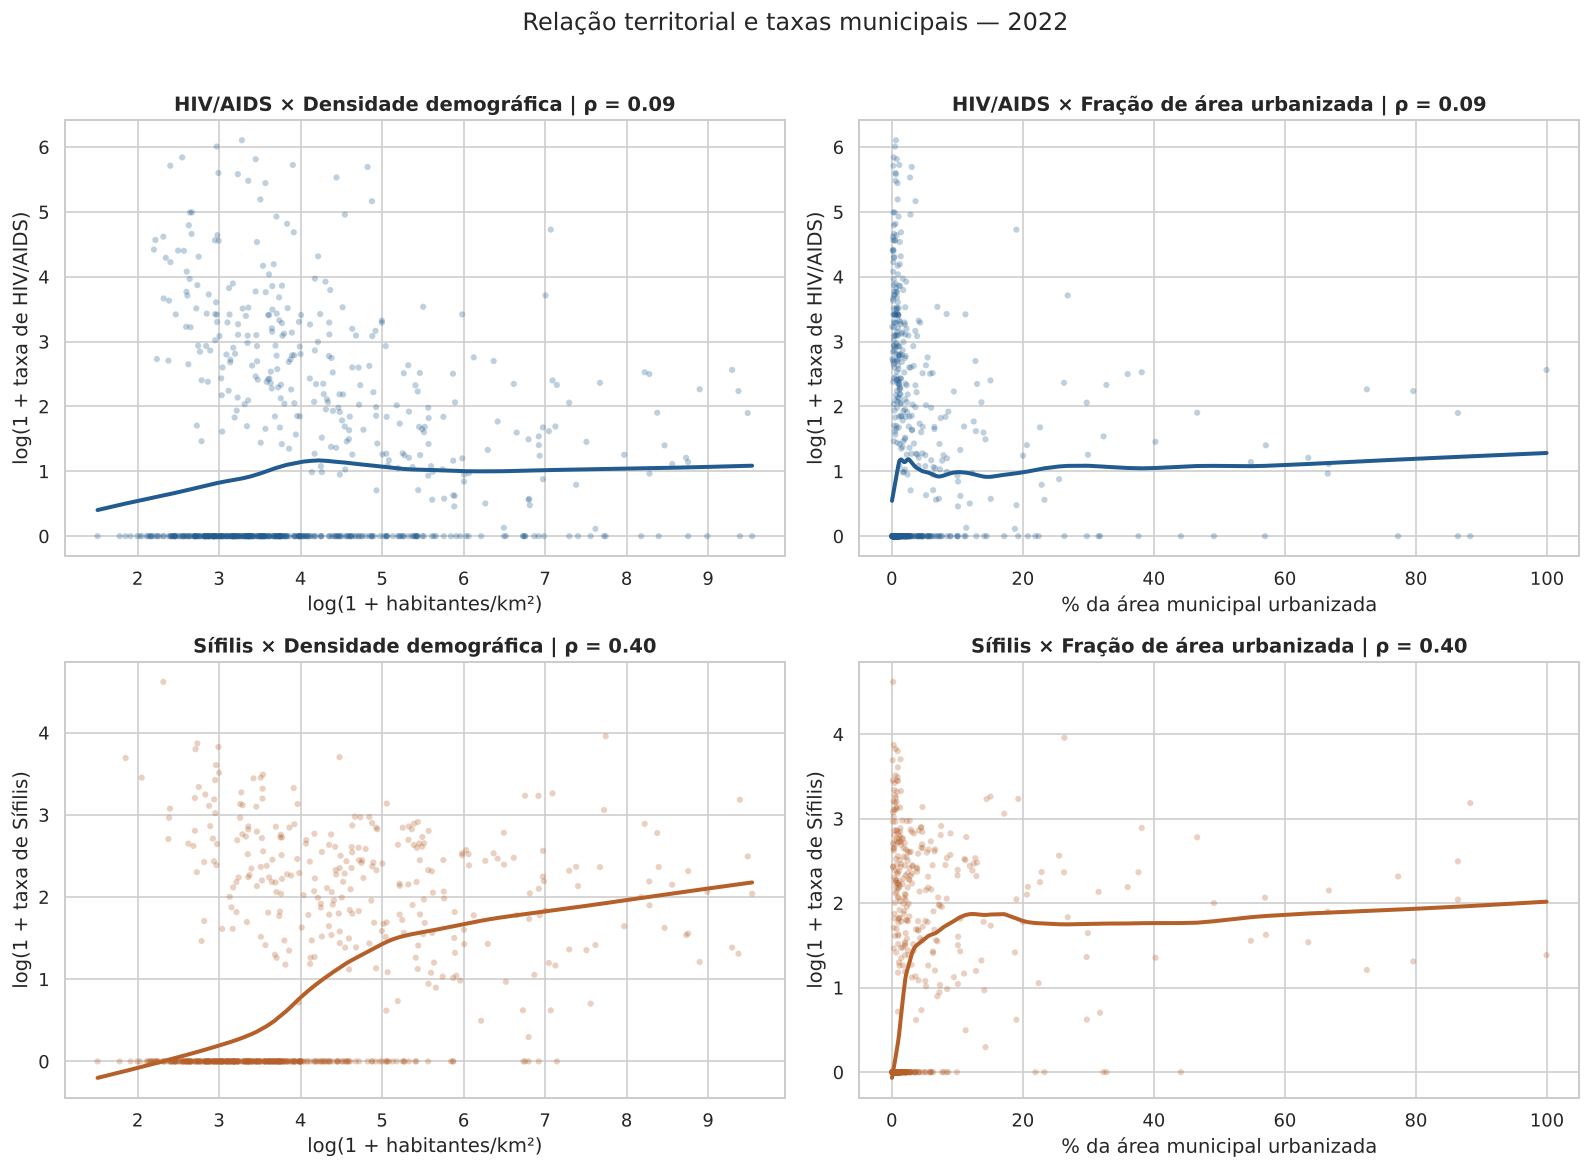

In [10]:
dados_ref["log_densidade"] = np.log1p(dados_ref["densidade"])
dados_ref["urbanizacao_pct_area"] = dados_ref["urbanizacao"] * 100
fig, eixos = plt.subplots(2, 2, figsize=(14, 10))
for i, desfecho in enumerate(("hiv_aids", "sifilis")):
    dados_ref[f"log_{desfecho}"] = np.log1p(dados_ref[desfecho])
    for j, (preditor, eixo_x) in enumerate((("densidade", "log_densidade"),
                                          ("urbanizacao", "urbanizacao_pct_area"))):
        ax = eixos[i, j]
        sns.regplot(data=dados_ref, x=eixo_x, y=f"log_{desfecho}", lowess=True,
                    ci=None, ax=ax, color=cores[desfecho],
                    scatter_kws={"s": 15, "alpha": 0.29, "edgecolor": "none"},
                    line_kws={"lw": 2.5})
        linha = correlacoes[(correlacoes.ano == ultimo_ano)
                            & (correlacoes.variavel_1 == desfecho)
                            & (correlacoes.variavel_2 == preditor)].iloc[0]
        ax.set(title=f"{rotulos[desfecho]} × {rotulos[preditor]} | ρ = {linha.rho_spearman:.2f}",
               ylabel=f"log(1 + taxa de {rotulos[desfecho]})",
               xlabel=("log(1 + habitantes/km²)" if j == 0 else "% da área municipal urbanizada"))
fig.suptitle(f"Relação territorial e taxas municipais — {ultimo_ano}", y=1.015, fontsize=15)
fig.tight_layout()
salvar_figura(f"06_dispersoes_indicadores_{ultimo_ano}.png")

## Etapa 11 — Gráfico 7: municípios com maiores taxas observadas no ano de referência (2022)

**O que será feito:** identificar os 10 maiores valores para cada doença em 2022.

**Atenção:** os resultados são *taxas por 100 mil*, não números absolutos de casos. A ordenação pode oscilar muito em municípios de pequena população e não deve ser usada isoladamente para definir prioridades sanitárias.

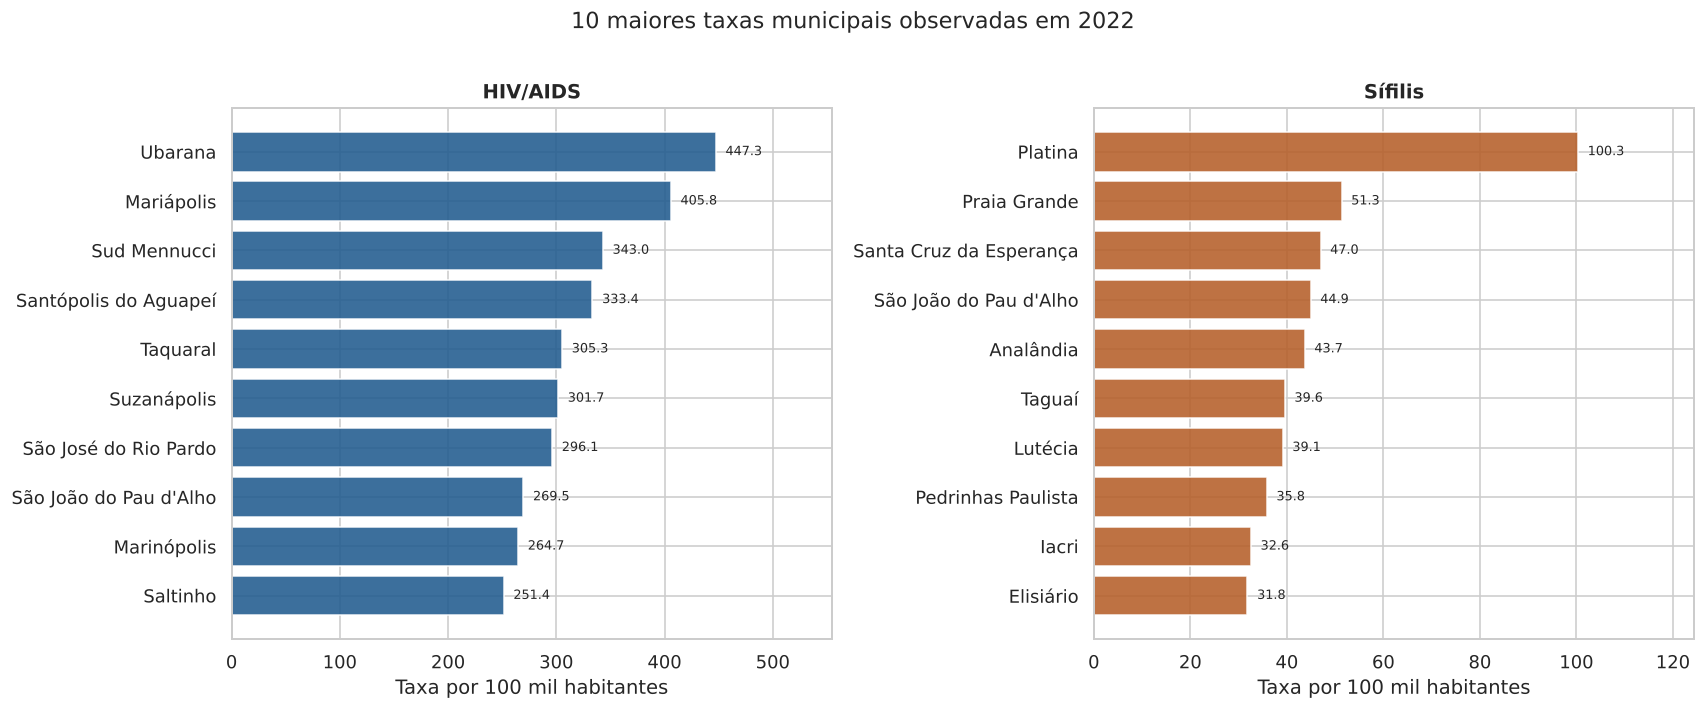

,indicador,municipio,CD_MUN,taxa_por_10mil
0,HIV/AIDS,Ubarana,3555356,447.343896
1,HIV/AIDS,Mariápolis,3528908,405.797101
2,HIV/AIDS,Sud Mennucci,3552304,343.004145
3,HIV/AIDS,Santópolis do Aguapeí,3548401,333.418825
4,HIV/AIDS,Taquaral,3553658,305.343511
5,HIV/AIDS,Suzanápolis,3552551,301.659125
6,HIV/AIDS,São José do Rio Pardo,3549706,296.121390
7,HIV/AIDS,São João do Pau d'Alho,3549300,269.541779
8,HIV/AIDS,Marinópolis,3529104,264.690312
9,HIV/AIDS,Saltinho,3545159,251.406680


In [11]:
top10_tabelas = []
fig, eixos = plt.subplots(1, 2, figsize=(15, 6.1))
for ax, variavel in zip(eixos, ("hiv_aids", "sifilis")):
    top = dados_ref.nlargest(10, variavel)[["municipio", "CD_MUN", variavel]].copy()
    top = top.rename(columns={variavel: "taxa_por_10mil"})
    top.insert(0, "indicador", rotulos[variavel])
    top10_tabelas.append(top)
    plotagem = top.sort_values("taxa_por_10mil")
    ax.barh(plotagem["municipio"], plotagem["taxa_por_10mil"], color=cores[variavel], alpha=0.88)
    ax.set(title=rotulos[variavel], xlabel="Taxa por 100 mil habitantes", ylabel="")
    ax.set_xlim(0, plotagem.taxa_por_10mil.max() * 1.24)
    for idx, valor in enumerate(plotagem["taxa_por_10mil"]):
        ax.text(valor + plotagem.taxa_por_10mil.max() * 0.02, idx, f"{valor:.1f}", va="center", fontsize=8)
fig.suptitle(f"10 maiores taxas municipais observadas em {ultimo_ano}", fontsize=14, y=1.01)
fig.tight_layout()
salvar_figura(f"07_top_10_municipios_{ultimo_ano}.png")
top10 = pd.concat(top10_tabelas, ignore_index=True)
salvar_tabela(top10, f"top10_taxas_{ultimo_ano}.csv")
display(top10)

## Etapa 12 — Modelagem exploratória (painel município–ano)

**O que será feito:** ajustar separadamente dois modelos de regressão linear para `log(1 + taxa)`, cada um com `log(1 + densidade)`, proporção territorial urbanizada (em **10 pontos percentuais**) e **efeitos fixos de ano**. Os erros-padrão serão robustos e agrupados por município, pois o mesmo município aparece em cinco anos.

**Leitura dos coeficientes:** são associações condicionais na escala `log(1+taxa)`; não são mudanças em número de casos nem efeitos causais. A análise não ajusta por idade, sexo, acesso a testes, notificação, desigualdade ou tamanho populacional. A medida de área urbanizada pode estar correlacionada com densidade. O modelo é **exploratório** e não uma inferência epidemiológica definitiva.

**Por que transformar as taxas?** Muitos zeros e caudas longas tornam a distribuição muito assimétrica. `log1p` aceita zero; ainda assim, o ajuste por mínimos quadrados não substitui modelos de contagem com numeradores e denominadores disponíveis.

In [12]:
modelagem = dados.copy()
modelagem["log_densidade"] = np.log1p(modelagem["densidade"])
modelagem["urbanizacao_10pp"] = modelagem["urbanizacao"] * 10  # 1 unidade = 10 pontos percentuais da área
modelos = {}
linhas_modelos = []
for desfecho in ("hiv_aids", "sifilis"):
    coluna = f"log_taxa_{desfecho}"
    modelagem[coluna] = np.log1p(modelagem[desfecho])
    formula = f"{coluna} ~ log_densidade + urbanizacao_10pp + C(ano)"
    m = smf.ols(formula, data=modelagem).fit(
        cov_type="cluster", cov_kwds={"groups": modelagem["CD_MUN"]}
    )
    modelos[desfecho] = m
    for termo in ("log_densidade", "urbanizacao_10pp"):
        ci_inf, ci_sup = m.conf_int().loc[termo]
        linhas_modelos.append({
            "desfecho": rotulos[desfecho], "variavel": termo,
            "coeficiente": m.params[termo], "ic95_inferior": ci_inf,
            "ic95_superior": ci_sup, "p_valor": m.pvalues[termo],
            "r2": m.rsquared, "observacoes": int(m.nobs),
            "municipios_agrupamento": modelagem.CD_MUN.nunique(),
        })

coeficientes = pd.DataFrame(linhas_modelos)
print("Coeficientes selecionados dos modelos, com erros-padrão agrupados por município:")
display(coeficientes.round(5))
salvar_tabela(coeficientes, "modelos_painel_coeficientes.csv")
print("\nR² de cada modelo e tamanho amostral:")
for desfecho, m in modelos.items():
    print(f"{rotulos[desfecho]}: n={int(m.nobs)}, R²={m.rsquared:.3f}")

Coeficientes selecionados dos modelos, com erros-padrão agrupados por município:


,desfecho,variavel,coeficiente,ic95_inferior,ic95_superior,p_valor,r2,observacoes,municipios_agrupamento
0,HIV/AIDS,log_densidade,0.01971,-0.06780,0.10722,0.65891,0.00337,3225,645
1,HIV/AIDS,urbanizacao_10pp,0.00685,-0.08186,0.09555,0.87976,0.00337,3225,645
2,Sífilis,log_densidade,0.38352,0.31683,0.45021,0.00000,0.13000,3225,645
3,Sífilis,urbanizacao_10pp,-0.15154,-0.22912,-0.07397,0.00013,0.13000,3225,645



R² de cada modelo e tamanho amostral:
HIV/AIDS: n=3225, R²=0.003
Sífilis: n=3225, R²=0.130


## Etapa 13 — Gráfico 8: coeficientes estimados e intervalos de confiança

**O que será feito:** apresentar os dois preditores de cada modelo com seu intervalo de confiança de 95%.

**Legenda:** pontos indicam coeficientes estimados na escala `log(1+taxa)`; barras horizontais representam intervalos de confiança de 95%; a linha vertical em zero representa ausência de associação no modelo. Os preditores **não estão na mesma unidade**, portanto seus tamanhos não devem ser comparados diretamente como “importância”.

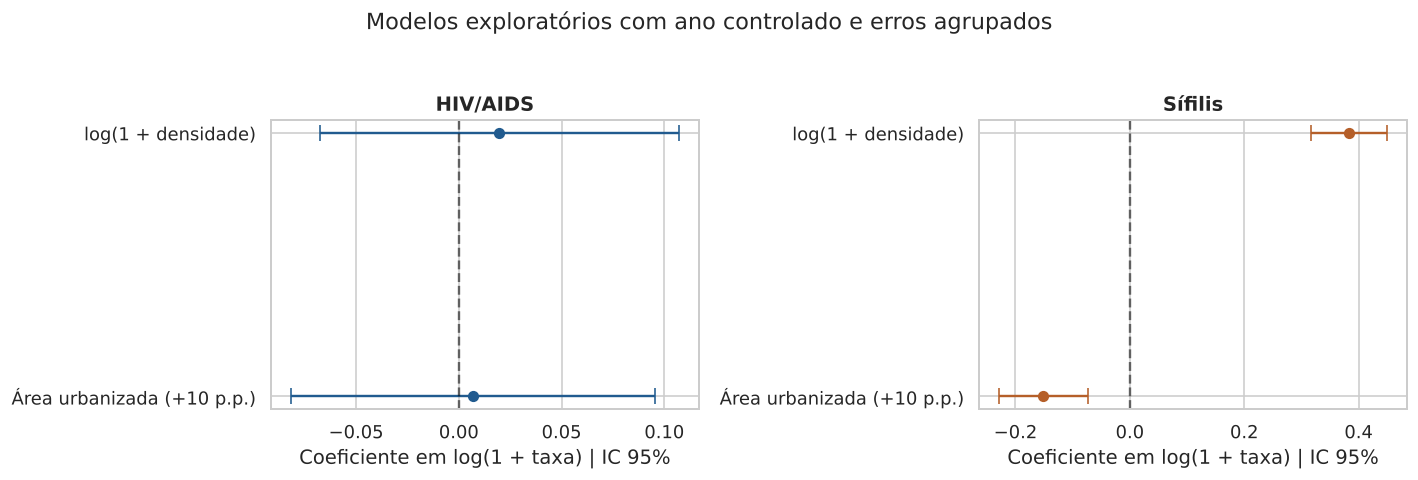

In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(12.5, 4), sharex=False)
nomes_termos = {
    "log_densidade": "log(1 + densidade)",
    "urbanizacao_10pp": "Área urbanizada (+10 p.p.)",
}
for ax, desfecho in zip(eixos, ("HIV/AIDS", "Sífilis")):
    t = coeficientes[coeficientes.desfecho == desfecho].reset_index(drop=True)
    for i, linha in t.iterrows():
        ax.errorbar(linha.coeficiente, i,
                    xerr=[[linha.coeficiente - linha.ic95_inferior],
                          [linha.ic95_superior - linha.coeficiente]],
                    fmt="o", capsize=5, color="#215B8F" if desfecho == "HIV/AIDS" else "#B55F29")
    ax.axvline(0, ls="--", color="black", alpha=0.55)
    ax.set_yticks(range(len(t)), labels=[nomes_termos[z] for z in t.variavel])
    ax.set(title=desfecho, xlabel="Coeficiente em log(1 + taxa) | IC 95%")
    ax.invert_yaxis()
fig.suptitle("Modelos exploratórios com ano controlado e erros agrupados", y=1.04, fontsize=14)
fig.tight_layout()
salvar_figura("08_coeficientes_modelos.png")

## Etapa 14 — Síntese automática dos principais resultados

**O que será feito:** montar um resumo textual reprodutível, preenchido pelos números que o notebook calculou. Assim, o texto será atualizado caso as planilhas sejam substituídas e o notebook seja reexecutado.

**Legenda de interpretação:** `ρ` é a correlação de Spearman; `p_FDR` é o valor de significância ajustado para múltiplos testes. O texto distingue **resultados observados** de **limitações de interpretação**.

In [14]:
def formatar(v, casas=2):
    return f"{v:.{casas}f}".replace(".", ",")

media_ref = resumo_taxas[resumo_taxas.ano == ultimo_ano].set_index("variavel")
media_ant = resumo_taxas[resumo_taxas.ano == ultimo_ano - 1].set_index("variavel")

linhas_relatorio = [
    "# Síntese automática — HIV/AIDS, sífilis e ambiente municipal — SP (2019–2023)",
    "",
    f"- Base: **{dados.CD_MUN.nunique()} municípios**, **{dados.ano.nunique()} anos**, "
    f"**{len(dados)} observações município–ano**.",
    "- Fontes: quatro planilhas fornecidas para este estudo, sem verificação externa de suas definições.",
    "- Os indicadores HIV/AIDS e sífilis são apresentados como taxas por **100 mil habitantes**; "
    "urbanização é **fração da área territorial urbanizada**, não da população urbana.",
    "",
    f"## Descrição de {ultimo_ano}",
]
for variavel in ("hiv_aids", "sifilis"):
    linha = media_ref.loc[variavel]
    anterior = media_ant.loc[variavel, "media"]
    variacao = 100 * (linha["media"] / anterior - 1) if anterior != 0 else float("nan")
    linhas_relatorio.append(
        f"- {rotulos[variavel]}: média municipal **{formatar(linha['media'])}** por 100 mil, "
        f"mediana **{formatar(linha['mediana'])}**, "
        f"**{formatar(linha['pct_zeros'], 1)}%** dos municípios com taxa zero. "
        f"Em comparação a {ultimo_ano - 1}, a média municipal variou **{formatar(variacao,1)}%** "
        "(comparação descritiva, não necessariamente mudança epidemiológica)."
    )

linhas_relatorio += ["", f"## Correlações de Spearman em {ultimo_ano} (ajuste FDR em 25 testes)"]
for _, l in correlacoes[correlacoes.ano == ultimo_ano].iterrows():
    linhas_relatorio.append(
        f"- {l.comparacao}: **ρ = {formatar(l.rho_spearman,3)}**, "
        f"p_FDR = {l.p_fdr:.3g}; "
        f"{'significativo' if l.significativo_fdr_5pct else 'não significativo'} ao nível de 5%."
    )
linhas_relatorio += [
    "", "## Modelagem exploratória", 
    "- Foram estimados modelos para log(1 + taxa), com efeitos de ano, densidade e fração de área urbanizada, "
    "e erros-padrão agrupados por município. Coeficientes e IC 95%: ver modelos_painel_coeficientes.csv.",
    "", "## Limitações importantes",
    "- Estudo ecológico, observacional, sem identificação de mecanismos causais.",
    "- Médias não ponderadas por população municipal **não são** taxas estaduais agregadas.",
    "- Taxas altas em municípios pequenos podem variar muito de ano para ano.",
    "- A grande frequência de zeros exige cautela; o significado de zero depende da fonte.",
    "- É necessário consultar metadados originais antes de denominar as taxas como incidência ou prevalência.",
    "- Não se avaliou completude de notificação, mudanças de definição, testagem ou estrutura etária; o período pandêmico é analisado na Parte II.",
    "- Os valores de 2023 repetem os de 2022 (integralmente para sífilis); por isso o ano de referência é 2022.",
]
relatorio = "\n".join(linhas_relatorio) + "\n"
(PASTA_RESULTADOS / "resumo_resultados.md").write_text(relatorio, encoding="utf-8")
display(Markdown(relatorio))

# Síntese automática — HIV/AIDS, sífilis e ambiente municipal — SP (2019–2023)

- Base: **645 municípios**, **5 anos**, **3225 observações município–ano**.
- Fontes: quatro planilhas fornecidas para este estudo, sem verificação externa de suas definições.
- Os indicadores HIV/AIDS e sífilis são apresentados como taxas por **100 mil habitantes**; urbanização é **fração da área territorial urbanizada**, não da população urbana.

## Descrição de 2022
- HIV/AIDS: média municipal **15,39** por 100 mil, mediana **0,00**, **54,0%** dos municípios com taxa zero. Em comparação a 2021, a média municipal variou **23,7%** (comparação descritiva, não necessariamente mudança epidemiológica).
- Sífilis: média municipal **4,83** por 100 mil, mediana **0,00**, **55,3%** dos municípios com taxa zero. Em comparação a 2021, a média municipal variou **-9,3%** (comparação descritiva, não necessariamente mudança epidemiológica).

## Correlações de Spearman em 2022 (ajuste FDR em 25 testes)
- HIV/AIDS × Sífilis: **ρ = 0,013**, p_FDR = 0.733; não significativo ao nível de 5%.
- HIV/AIDS × Densidade demográfica: **ρ = 0,094**, p_FDR = 0.0233; significativo ao nível de 5%.
- HIV/AIDS × Fração de área urbanizada: **ρ = 0,091**, p_FDR = 0.0263; significativo ao nível de 5%.
- Sífilis × Densidade demográfica: **ρ = 0,403**, p_FDR = 7.28e-26; significativo ao nível de 5%.
- Sífilis × Fração de área urbanizada: **ρ = 0,404**, p_FDR = 5.69e-26; significativo ao nível de 5%.

## Modelagem exploratória
- Foram estimados modelos para log(1 + taxa), com efeitos de ano, densidade e fração de área urbanizada, e erros-padrão agrupados por município. Coeficientes e IC 95%: ver modelos_painel_coeficientes.csv.

## Limitações importantes
- Estudo ecológico, observacional, sem identificação de mecanismos causais.
- Médias não ponderadas por população municipal **não são** taxas estaduais agregadas.
- Taxas altas em municípios pequenos podem variar muito de ano para ano.
- A grande frequência de zeros exige cautela; o significado de zero depende da fonte.
- É necessário consultar metadados originais antes de denominar as taxas como incidência ou prevalência.
- Não se avaliou completude de notificação, mudanças de definição, testagem ou estrutura etária; o período pandêmico é analisado na Parte II.
- Os valores de 2023 repetem os de 2022 (integralmente para sífilis); por isso o ano de referência é 2022.


## Etapa 15 — Arquivos gerados e próximos passos científicos

**O que foi produzido:** uma tabela integrada município–ano, estatísticas anuais, controle de qualidade, correlações corrigidas para múltiplos testes, rankings, coeficientes de modelos, oito arquivos PNG com gráficos e um resumo em Markdown. O diretório `resultados/` pode ser compactado e distribuído com o notebook.

**Para aprofundar a pesquisa:** conferir a definição dos indicadores na fonte; obter população municipal por ano e números absolutos de casos para calcular taxas estaduais ponderadas e intervalos de incerteza; examinar a estabilidade dos extremos; considerar estrutura etária, testagem e cobertura da vigilância. **Não é possível inferir características individuais dos moradores a partir destas correlações municipais.**

In [15]:
produzidos = sorted(x.relative_to(PASTA_PROJETO).as_posix() for x in PASTA_RESULTADOS.rglob("*") if x.is_file())
print(f"Total de arquivos de resultado: {len(produzidos)}")
for nome in produzidos:
    print("•", nome)
print("\nNotebook finalizado. Todas as tabelas, gráficos e conclusões foram calculados das planilhas fornecidas.")

Total de arquivos de resultado: 15
• resultados/base_municipio_ano.csv
• resultados/correlacoes_spearman_por_ano.csv
• resultados/estatisticas_descritivas_anuais.csv
• resultados/graficos/01_evolucao_anual.png
• resultados/graficos/02_distribuicao_boxplots.png
• resultados/graficos/03_percentual_zeros.png
• resultados/graficos/04_evolucao_correlacoes.png
• resultados/graficos/05_matriz_correlacao_2022.png
• resultados/graficos/06_dispersoes_indicadores_2022.png
• resultados/graficos/07_top_10_municipios_2022.png
• resultados/graficos/08_coeficientes_modelos.png
• resultados/modelos_painel_coeficientes.csv
• resultados/qualidade_dos_dados.csv
• resultados/resumo_resultados.md
• resultados/top10_taxas_2022.csv

Notebook finalizado. Todas as tabelas, gráficos e conclusões foram calculados das planilhas fornecidas.


---
# Parte II — Período pandêmico e distribuição espacial

**Objetivo desta parte:** (i) evidenciar o comportamento das notificações no período da pandemia de COVID-19; (ii) destacar os municípios com taxas persistentemente elevadas; e (iii) localizar esses municípios no território paulista, por mapas estáticos, análise de autocorrelação espacial e um mapa interativo com busca por município.

**Períodos adotados:** pré-pandemia (2019), pandemia (2020–2021) e pós-pandemia (2022–2023).

**Pacotes adicionais:** `geopandas`, `mapclassify`, `folium`, `libpysal` e `esda`. Se necessário: `!pip install geopandas mapclassify folium libpysal esda`.

> **Interpretação:** variações no período pandêmico refletem, em grande parte, mudanças na **notificação** (menor procura por serviços, redução da testagem, reorganização da vigilância), e não necessariamente na **transmissão**. Com um único ano pré-pandêmico, não é possível estimar a tendência anterior; os resultados desta parte são descritivos.

In [16]:
import unicodedata
import urllib.request
import geopandas as gpd
import matplotlib.patches as mpatches
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import wilcoxon, chi2, spearmanr

ANOS_PANDEMIA = [2020, 2021]
ANOS_REFERENCIA = [2019, 2022]          # linha de base não pandêmica (justificativa na Etapa 18)
PERIODO = {2019: "Pré-pandemia", 2020: "Pandemia", 2021: "Pandemia",
           2022: "Pós-pandemia", 2023: "Pós-pandemia"}
COR_PANDEMIA = "#C0392B"
CORRIGIR_PERMUTACAO_SP = True           # ver Etapa 17; False mantém a planilha como está
DESFECHOS = ("hiv_aids", "sifilis")
CMAP = {"hiv_aids": "Blues", "sifilis": "Oranges"}


def sombrear_pandemia(ax, rotulo=True):
    # Faixa vertical marcando 2020–2021 em gráficos com o ano no eixo x
    ax.axvspan(2019.5, 2021.5, color=COR_PANDEMIA, alpha=0.08, zorder=0)
    if rotulo:
        ax.text(2020.5, 0.98, "Pandemia", transform=ax.get_xaxis_transform(),
                ha="center", va="top", color=COR_PANDEMIA, fontsize=9, weight="bold")


def normalizar(texto):
    # Remove acentos e caixa, para busca de municípios pelo nome
    return unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode().lower().strip()

## Etapa 16 — Malha municipal e reconstrução da população e dos casos

**O que será feito:** obter a malha dos 645 municípios paulistas, calcular a área de cada município (projeção cônica de Albers, SIRGAS 2000, EPSG:5880) e reconstruir a **população** (`densidade × área`) e o **número de casos** (`taxa × população / escala`).

**Por que isso importa:** com casos e população é possível calcular **taxas estaduais ponderadas** (o que a Parte I não podia fazer), **suavizar** as taxas de municípios pequenos e comparar casos observados com esperados.

**Fonte da malha:** arquivo GeoJSON derivado das malhas do IBGE (repositório `tbrugz/geodata-br`), salvo em `dados/` na primeira execução. A área calculada difere ligeiramente da área oficial do IBGE; a população reconstruída é, portanto, aproximada.

In [17]:
URL_MALHA = "https://raw.githubusercontent.com/tbrugz/geodata-br/master/geojson/geojs-35-mun.json"
ARQ_MALHA = PASTA_PROJETO / "dados" / "malha_municipios_SP.geojson"
if not ARQ_MALHA.is_file():
    ARQ_MALHA.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL_MALHA, ARQ_MALHA)

malha = gpd.read_file(ARQ_MALHA)
malha["CD_MUN"] = malha["id"].astype(str).str.zfill(7)
malha["geometry"] = malha.geometry.make_valid()          # corrige polígonos litorâneos inválidos
malha = malha[["CD_MUN", "geometry"]].copy()
malha["area_km2"] = malha.to_crs(5880).area / 1e6
assert set(malha.CD_MUN) == set(dados.CD_MUN), "Códigos da malha não coincidem com a base"

esp = dados.merge(malha[["CD_MUN", "area_km2"]], on="CD_MUN", how="left", validate="many_to_one")
esp["populacao"] = esp["densidade"] * esp["area_km2"]
print(f"Malha: {len(malha)} municípios | população reconstruída do estado:")
display(esp.groupby("ano")["populacao"].sum().div(1e6).round(2).rename("milhões de habitantes").to_frame())

Malha: 645 municípios | população reconstruída do estado:


,milhões de habitantes
ano,
2019,46.20
2020,46.58
2021,46.94
2022,46.31
2023,44.68


### Verificação da escala das taxas

Casos são números inteiros. Se as taxas estivessem de fato **por 10 mil habitantes**, os casos implícitos (`taxa × população / 10.000`) deveriam assumir valores como 1, 2, 3... Abaixo verificamos qual escala produz contagens coerentes.

In [18]:
verificacao = []
for v in DESFECHOS:
    positivos = esp[esp[v] > 0]
    casos_10mil = positivos[v] * positivos["populacao"] / 1e4
    verificacao.append({
        "indicador": rotulos[v],
        "menor nº de casos implícito (escala 10 mil)": casos_10mil.min(),
        "% de contagens múltiplas de 10 (escala 10 mil)":
            100 * ((casos_10mil / 10 - (casos_10mil / 10).round()).abs() < 0.15).mean(),
    })
verificacao = pd.DataFrame(verificacao)
display(verificacao.round(2))

if (verificacao["% de contagens múltiplas de 10 (escala 10 mil)"] > 90).all():
    ESCALA = 100_000
    print("RESULTADO: na escala de 10 mil, nenhum município teria registrado de 1 a 9 casos e quase todas as "
          "contagens seriam múltiplas de 10 — o que não é plausível. As taxas são compatíveis com casos "
          "por 100 MIL habitantes. A Parte II usa essa escala; os rótulos da Parte I devem ser revistos.")
else:
    ESCALA = 10_000
    print("As taxas são compatíveis com a escala de 10 mil habitantes.")
UNIDADE_TAXA = f"por {ESCALA // 1000} mil hab."

,indicador,menor nº de casos implícito (escala 10 mil),% de contagens múltiplas de 10 (escala 10 mil)
0,HIV/AIDS,9.68,94.96
1,Sífilis,9.78,92.69


RESULTADO: na escala de 10 mil, nenhum município teria registrado de 1 a 9 casos e quase todas as contagens seriam múltiplas de 10 — o que não é plausível. As taxas são compatíveis com casos por 100 MIL habitantes. A Parte II usa essa escala; os rótulos da Parte I devem ser revistos.


## Etapa 17 — Correção da permutação entre São Paulo (capital) e São Miguel Arcanjo

**Problema identificado:** em 2019–2022, São Miguel Arcanjo apresentava taxas de HIV/AIDS da ordem de 3.400–4.200 (valores posteriormente divididos por 1.000 na planilha), enquanto a capital tinha taxas próximas de zero. Em 2023, a capital passa a ter valor plausível.

**Evidência:** convertendo as taxas em casos, o valor registrado na linha de São Miguel Arcanjo corresponde a um número **inteiro** de casos *com a população de São Miguel Arcanjo*, e o valor da capital a um número inteiro *com a população da capital* — o padrão esperado quando as linhas de casos foram trocadas antes do cálculo das taxas. Se `CORRIGIR_PERMUTACAO_SP = True`, os casos são devolvidos ao município correto e as taxas recalculadas. **Confirmar no DATASUS/TabNet.**

In [19]:
COD_SMA, COD_CAP = "3550209", "3550308"
linhas = []
for ano in (2019, 2020, 2021, 2022):
    i_sma = esp.index[(esp.CD_MUN == COD_SMA) & (esp.ano == ano)][0]
    i_cap = esp.index[(esp.CD_MUN == COD_CAP) & (esp.ano == ano)][0]
    taxa_sma = esp.at[i_sma, "hiv_aids"]
    taxa_sma_original = taxa_sma * 1000 if taxa_sma < 100 else taxa_sma   # desfaz a divisão por 1.000
    casos_linha_sma = taxa_sma_original * esp.at[i_sma, "populacao"] / ESCALA
    casos_linha_cap = esp.at[i_cap, "hiv_aids"] * esp.at[i_cap, "populacao"] / ESCALA
    linhas.append({"ano": ano, "casos na linha de S. M. Arcanjo": casos_linha_sma,
                   "casos na linha da capital": casos_linha_cap})
    if CORRIGIR_PERMUTACAO_SP:
        esp.at[i_cap, "hiv_aids"] = casos_linha_sma * ESCALA / esp.at[i_cap, "populacao"]
        esp.at[i_sma, "hiv_aids"] = casos_linha_cap * ESCALA / esp.at[i_sma, "populacao"]

display(pd.DataFrame(linhas).round(2))
print("Correção aplicada." if CORRIGIR_PERMUTACAO_SP else "Correção NÃO aplicada (CORRIGIR_PERMUTACAO_SP = False).")
display(esp[esp.CD_MUN.isin([COD_SMA, COD_CAP])]
        .pivot(index="municipio", columns="ano", values="hiv_aids").round(2))

,ano,casos na linha de S. M. Arcanjo,casos na linha da capital
0,2019,1401.46,4.03
1,2020,1140.26,0.00
2,2021,1400.46,3.03
3,2022,1365.30,0.00


Correção aplicada.


ano,2019,2020,2021,2022,2023
municipio,,,,,
São Miguel Arcanjo,12.19,0.00,9.11,0.0,0.00
São Paulo,11.34,9.17,11.20,11.1,11.87


### Casos, taxas suavizadas e classes de porte

**Suavização bayesiana empírica (estimador global de Marshall):** em municípios pequenos, um único caso altera muito a taxa. A suavização aproxima cada taxa da média estadual na proporção da sua instabilidade: municípios populosos praticamente mantêm a taxa observada; municípios pequenos são "puxados" para a média. As taxas suavizadas (`*_eb`) são usadas nos mapas e rankings; as brutas permanecem na base.

In [20]:
def bayes_empirico(casos, populacao):
    # Estimador bayesiano empírico global de Marshall (1991); retorna taxa por habitante
    m = casos.sum() / populacao.sum()
    r = casos / populacao
    s2 = (populacao * (r - m) ** 2).sum() / populacao.sum() - m / populacao.mean()
    A = max(s2, 0.0)
    peso = A / (A + m / populacao)
    return peso * r + (1 - peso) * m

for v in DESFECHOS:
    esp[f"casos_{v}"] = (esp[v] * esp["populacao"] / ESCALA).round()
    esp[f"{v}_eb"] = esp.groupby("ano", group_keys=False).apply(
        lambda g: bayes_empirico(g[f"casos_{v}"], g["populacao"]) * ESCALA)

esp["periodo"] = esp["ano"].map(PERIODO)
esp["porte"] = pd.cut(esp["populacao"], [0, 10e3, 50e3, 100e3, 500e3, np.inf],
                      labels=["< 10 mil", "10–50 mil", "50–100 mil", "100–500 mil", "> 500 mil"])
print("Casos reconstruídos por ano:")
display(esp.groupby("ano")[[f"casos_{v}" for v in DESFECHOS]].sum().astype(int)
        .rename(columns={"casos_hiv_aids": "HIV/AIDS", "casos_sifilis": "Sífilis"}))

Casos reconstruídos por ano:


,HIV/AIDS,Sífilis
ano,,
2019,3589,3210
2020,2938,3362
2021,3223,3566
2022,3479,3500
2023,3485,3500


### Verificação de integridade temporal das séries

**O que será feito:** dois testes simples de consistência, possíveis agora que temos contagens de casos.

1. **Repetição entre anos consecutivos:** em séries reais, é raro um município registrar exatamente o mesmo número de casos em dois anos seguidos. Comparamos a proporção de repetições 2022→2023 com a observada nos demais pares de anos.
2. **Municípios populosos sem casos:** municípios com mais de 100 mil habitantes sem nenhum caso de HIV/AIDS em quatro anos seguidos são epidemiologicamente implausíveis e indicam casos atribuídos a outro município.

Os resultados condicionam a interpretação de toda a Parte II.

In [21]:
largo_casos = {v: esp.pivot(index="CD_MUN", columns="ano", values=f"casos_{v}") for v in DESFECHOS}
linhas = []
for v in DESFECHOS:
    c = largo_casos[v]
    for a in ANOS[1:]:
        com_casos = c[a - 1] > 0
        linhas.append({"indicador": rotulos[v], "par de anos": f"{a-1}→{a}",
                       "% de municípios com contagem idêntica": 100 * (c.loc[com_casos, a] == c.loc[com_casos, a - 1]).mean()})
repeticao = pd.DataFrame(linhas).pivot(index="par de anos", columns="indicador",
                                         values="% de municípios com contagem idêntica")
display(repeticao.round(1))

grandes = esp[esp.ano == 2022].set_index("CD_MUN")["populacao"] > 100_000
c = largo_casos["hiv_aids"].loc[grandes[grandes].index]
sem_casos = c[c[[2019, 2020, 2021, 2022]].sum(axis=1) == 0]
nomes_mun = esp.drop_duplicates("CD_MUN").set_index("CD_MUN")["municipio"]
print(f"Municípios com > 100 mil hab.: {grandes.sum()} | sem nenhum caso de HIV/AIDS em 2019–2022: {len(sem_casos)}")
display(sem_casos.assign(municipio=nomes_mun).set_index("municipio").astype(int))

# Correlação entre casos e população: deveria ser forte e estável entre os anos
corr_pop = pd.DataFrame({rotulos[v]: [spearmanr(largo_casos[v][a], esp[esp.ano == a].set_index("CD_MUN")["populacao"].reindex(largo_casos[v].index))[0]
                                      for a in ANOS] for v in DESFECHOS}, index=ANOS)
print("Correlação de Spearman entre nº de casos e população, por ano (esperada: alta e estável):")
display(corr_pop.round(3))

ALERTAS = []
if repeticao["Sífilis"].loc["2022→2023"] > 90:
    ALERTAS.append("Sífilis: os casos de 2023 são cópia dos de 2022 (repetição em praticamente todos os municípios).")
if repeticao["HIV/AIDS"].loc["2022→2023"] > 2 * repeticao["HIV/AIDS"].drop("2022→2023").max():
    ALERTAS.append("HIV/AIDS: 2023 repete 2022 em proporção muito acima dos demais anos (cópia parcial).")
if len(sem_casos) > 0:
    ALERTAS.append(f"HIV/AIDS: {len(sem_casos)} municípios com mais de 100 mil habitantes sem casos em 2019–2022, "
                   "enquanto municípios muito pequenos têm taxas extremas que desaparecem em 2023 — padrão "
                   "compatível com casos atribuídos ao município errado (como na capital/S. M. Arcanjo).")
print("\n".join("ALERTA — " + a for a in ALERTAS) if ALERTAS else "Nenhuma inconsistência detectada.")

indicador,HIV/AIDS,Sífilis
par de anos,,
2019→2020,11.7,13.2
2020→2021,14.1,14.0
2021→2022,17.4,14.7
2022→2023,53.5,100.0


Municípios com > 100 mil hab.: 80 | sem nenhum caso de HIV/AIDS em 2019–2022: 10


ano,2019,2020,2021,2022,2023
municipio,,,,,
Marília,0,0,0,0,14
Paulínia,0,0,0,0,0
Praia Grande,0,0,0,0,4
Santa Bárbara d'Oeste,0,0,0,0,1
Santos,0,0,0,0,13
Sorocaba,0,0,0,0,2
Sumaré,0,0,0,0,24
São Carlos,0,0,0,0,20
São Vicente,0,0,0,0,6


Correlação de Spearman entre nº de casos e população, por ano (esperada: alta e estável):


,HIV/AIDS,Sífilis
2019,0.323,0.637
2020,0.309,0.677
2021,0.301,0.648
2022,0.325,0.684
2023,0.581,0.685


ALERTA — Sífilis: os casos de 2023 são cópia dos de 2022 (repetição em praticamente todos os municípios).
ALERTA — HIV/AIDS: 2023 repete 2022 em proporção muito acima dos demais anos (cópia parcial).
ALERTA — HIV/AIDS: 10 municípios com mais de 100 mil habitantes sem casos em 2019–2022, enquanto municípios muito pequenos têm taxas extremas que desaparecem em 2023 — padrão compatível com casos atribuídos ao município errado (como na capital/S. M. Arcanjo).


## Etapa 18 — Gráfico 9: taxa estadual ponderada e o período pandêmico

**O que será feito:** calcular a taxa do **estado** (soma dos casos / soma da população), com intervalo de confiança de 95% (Poisson exato), e compará-la com a **média municipal** usada na Parte I.

**Legenda:** faixa vermelha = pandemia; linha cheia = taxa estadual; faixa colorida = IC 95%; linha tracejada = média municipal não ponderada. Para HIV/AIDS, a linha pontilhada exclui a capital, para mostrar quanto do padrão estadual depende dela.

**Por que a linha de base usa 2019 e 2022, e não 2023?** A verificação de integridade mostrou que os valores de 2023 repetem os de 2022 (integralmente para sífilis, parcialmente para HIV/AIDS); 2023 não é, portanto, uma observação independente. Além disso, a queda abrupta da média municipal de HIV/AIDS em 2023, que a taxa ponderada não acompanha, decorre do desaparecimento das taxas extremas de municípios pequenos — mais um indício dos problemas de atribuição apontados acima.

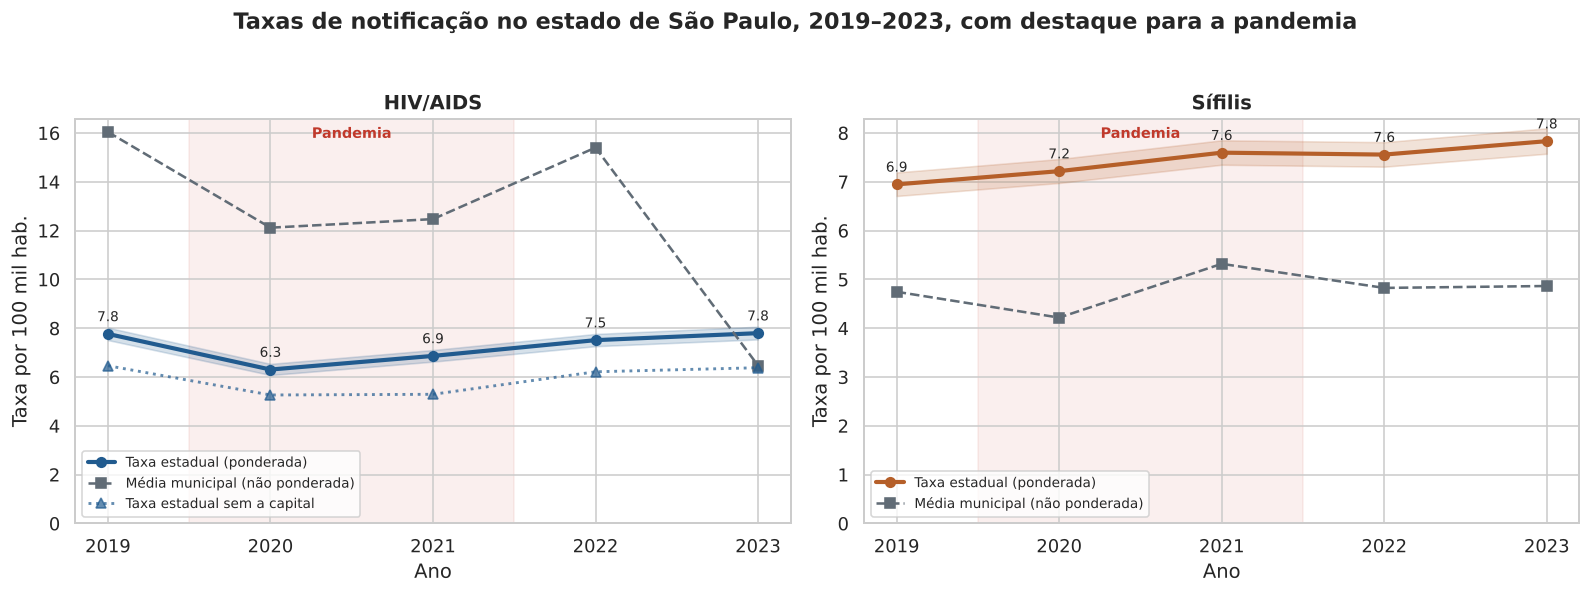

,indicador,ano,casos,taxa,ic_inf,ic_sup
0,HIV/AIDS,2019,3589.0,7.77,7.52,8.03
1,HIV/AIDS,2020,2938.0,6.31,6.08,6.54
2,HIV/AIDS,2021,3223.0,6.87,6.63,7.11
3,HIV/AIDS,2022,3479.0,7.51,7.26,7.77
4,HIV/AIDS,2023,3485.0,7.80,7.54,8.06
5,Sífilis,2019,3210.0,6.95,6.71,7.19
6,Sífilis,2020,3362.0,7.22,6.98,7.47
7,Sífilis,2021,3566.0,7.60,7.35,7.85
8,Sífilis,2022,3500.0,7.56,7.31,7.81
9,Sífilis,2023,3500.0,7.83,7.58,8.10


In [22]:
def ic_poisson(casos, alfa=0.05):
    inf = chi2.ppf(alfa / 2, 2 * casos) / 2 if casos > 0 else 0.0
    sup = chi2.ppf(1 - alfa / 2, 2 * (casos + 1)) / 2
    return inf, sup

def taxa_agregada(tab, v):
    linhas = []
    for ano, g in tab.groupby("ano"):
        c, p = g[f"casos_{v}"].sum(), g["populacao"].sum()
        li, ls = ic_poisson(c)
        linhas.append({"ano": ano, "casos": c, "taxa": c / p * ESCALA,
                       "ic_inf": li / p * ESCALA, "ic_sup": ls / p * ESCALA})
    return pd.DataFrame(linhas)

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
tabelas_estado = []
for ax, v in zip(eixos, DESFECHOS):
    est = taxa_agregada(esp, v)
    est.insert(0, "indicador", rotulos[v]); tabelas_estado.append(est)
    sombrear_pandemia(ax)
    ax.fill_between(est.ano, est.ic_inf, est.ic_sup, color=cores[v], alpha=0.18)
    ax.plot(est.ano, est.taxa, "o-", lw=2.6, color=cores[v], label="Taxa estadual (ponderada)")
    media_mun = esp.groupby("ano")[v].mean()
    ax.plot(media_mun.index, media_mun.values, "s--", lw=1.6, color="#616C76", label="Média municipal (não ponderada)")
    if v == "hiv_aids":
        sem_cap = taxa_agregada(esp[esp.CD_MUN != COD_CAP], v)
        ax.plot(sem_cap.ano, sem_cap.taxa, "^:", lw=1.8, color=cores[v], alpha=0.7, label="Taxa estadual sem a capital")
    for a, t in zip(est.ano, est.taxa):
        ax.annotate(f"{t:.1f}", (a, t), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8.5)
    ax.set(title=rotulos[v], xlabel="Ano", ylabel=f"Taxa {UNIDADE_TAXA}", xticks=ANOS)
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=8.5, loc="lower left")
fig.suptitle("Taxas de notificação no estado de São Paulo, 2019–2023, com destaque para a pandemia",
             y=1.03, fontsize=14, weight="bold")
fig.tight_layout()
salvar_figura("09_taxa_estadual_pandemia.png")
taxa_estado = pd.concat(tabelas_estado, ignore_index=True)
salvar_tabela(taxa_estado, "taxa_estadual_ponderada.csv")
display(taxa_estado.round(2))

## Etapa 19 — Gráfico 10: casos observados versus esperados na pandemia

**O que será feito:** estimar quantos casos seriam esperados em 2020–2021 se as taxas tivessem permanecido no nível da linha de base (2019 e 2022), e comparar com os observados: **razão O/E** = observados / esperados, com IC 95% (Poisson exato).

**Leitura:** O/E < 1 indica **déficit de notificação** na pandemia; O/E > 1, excesso. O cálculo é feito para o estado e para estratos de **porte populacional** e de **urbanização** (quartis), para verificar se o déficit foi desigual no território.

**Teste complementar:** teste de postos sinalizados de Wilcoxon pareado, comparando, em cada município, a taxa suavizada média da pandemia com a da linha de base.

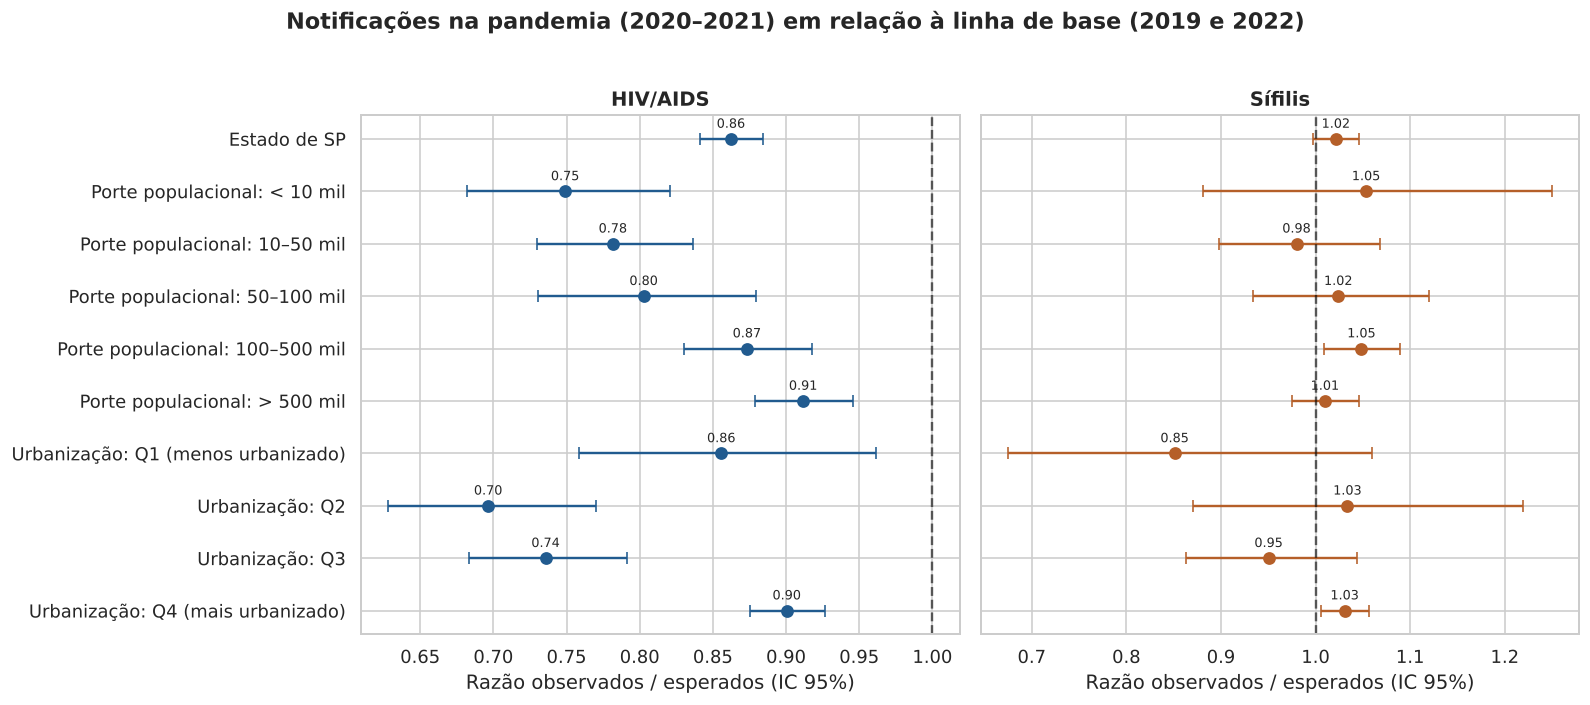

,indicador,grupo,estrato,observados,esperados,OE,ic_inf,ic_sup
0,HIV/AIDS,Estratificação,Estado de SP,6161.0,7144.484,0.862,0.841,0.884
1,HIV/AIDS,Porte populacional,< 10 mil,458.0,611.448,0.749,0.682,0.821
2,HIV/AIDS,Porte populacional,10–50 mil,845.0,1081.047,0.782,0.730,0.836
3,HIV/AIDS,Porte populacional,50–100 mil,457.0,569.342,0.803,0.731,0.880
4,HIV/AIDS,Porte populacional,100–500 mil,1537.0,1760.088,0.873,0.830,0.918
5,HIV/AIDS,Porte populacional,> 500 mil,2864.0,3141.441,0.912,0.879,0.946
6,HIV/AIDS,Urbanização,Q1 (menos urbanizado),282.0,329.542,0.856,0.759,0.962
7,HIV/AIDS,Urbanização,Q2,380.0,545.625,0.696,0.628,0.770
8,HIV/AIDS,Urbanização,Q3,727.0,988.187,0.736,0.683,0.791
9,HIV/AIDS,Urbanização,Q4 (mais urbanizado),4772.0,5299.463,0.900,0.875,0.926



Wilcoxon pareado — taxa suavizada média: pandemia vs linha de base (por município)
  HIV/AIDS : mediana da diferença = -0.02 por 100 mil hab. | municípios com queda = 52% | p = 5.84e-06
  Sífilis  : mediana da diferença = +0.16 por 100 mil hab. | municípios com queda = 34% | p = 0.000136


In [23]:
def razao_oe(tab, v):
    base = tab[tab.ano.isin(ANOS_REFERENCIA)]
    pand = tab[tab.ano.isin(ANOS_PANDEMIA)]
    taxa_base = base[f"casos_{v}"].sum() / base["populacao"].sum()
    esperados = taxa_base * pand["populacao"].sum()
    observados = pand[f"casos_{v}"].sum()
    li, ls = ic_poisson(observados)
    return {"observados": observados, "esperados": esperados,
            "OE": observados / esperados, "ic_inf": li / esperados, "ic_sup": ls / esperados}

esp["urbanizacao_quartil"] = esp.groupby("ano")["urbanizacao"].transform(
    lambda s: pd.qcut(s, 4, labels=["Q1 (menos urbanizado)", "Q2", "Q3", "Q4 (mais urbanizado)"]))
porte_fixo = esp[esp.ano == 2022].set_index("CD_MUN")["porte"]        # porte segundo o Censo 2022
urb_fixa = esp[esp.ano == 2022].set_index("CD_MUN")["urbanizacao_quartil"]
esp["porte_2022"] = esp["CD_MUN"].map(porte_fixo)
esp["urb_quartil_2022"] = esp["CD_MUN"].map(urb_fixa)

linhas_oe = []
for v in DESFECHOS:
    linhas_oe.append({"indicador": rotulos[v], "grupo": "Estratificação", "estrato": "Estado de SP", **razao_oe(esp, v)})
    for estrato, g in esp.groupby("porte_2022", observed=True):
        linhas_oe.append({"indicador": rotulos[v], "grupo": "Porte populacional", "estrato": estrato, **razao_oe(g, v)})
    for estrato, g in esp.groupby("urb_quartil_2022", observed=True):
        linhas_oe.append({"indicador": rotulos[v], "grupo": "Urbanização", "estrato": estrato, **razao_oe(g, v)})
oe = pd.DataFrame(linhas_oe)
salvar_tabela(oe, "razao_observado_esperado_pandemia.csv")

fig, eixos = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, v in zip(eixos, DESFECHOS):
    t = oe[oe.indicador == rotulos[v]].reset_index(drop=True)
    y = np.arange(len(t))[::-1]
    ax.errorbar(t.OE, y, xerr=[t.OE - t.ic_inf, t.ic_sup - t.OE], fmt="o", color=cores[v], capsize=4, ms=7)
    ax.axvline(1, ls="--", color="black", alpha=0.6)
    for yi, (oe_i, obs) in zip(y, zip(t.OE, t.observados)):
        ax.annotate(f"{oe_i:.2f}", (oe_i, yi), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
    ax.set_yticks(y, labels=[f"{g}: {e}" if g != "Estratificação" else e for g, e in zip(t.grupo, t.estrato)])
    ax.set(title=rotulos[v], xlabel="Razão observados / esperados (IC 95%)")
fig.suptitle("Notificações na pandemia (2020–2021) em relação à linha de base (2019 e 2022)",
             y=1.02, fontsize=14, weight="bold")
fig.tight_layout()
salvar_figura("10_observado_esperado_pandemia.png")
display(oe.round(3))

# Teste pareado por município (taxas suavizadas)
print("\nWilcoxon pareado — taxa suavizada média: pandemia vs linha de base (por município)")
for v in DESFECHOS:
    base = esp[esp.ano.isin(ANOS_REFERENCIA)].groupby("CD_MUN")[f"{v}_eb"].mean()
    pand = esp[esp.ano.isin(ANOS_PANDEMIA)].groupby("CD_MUN")[f"{v}_eb"].mean()
    estat, p = wilcoxon(pand, base)
    print(f"  {rotulos[v]:9s}: mediana da diferença = {np.median(pand - base):+.2f} {UNIDADE_TAXA} | "
          f"municípios com queda = {(pand < base).mean():.0%} | p = {p:.3g}")

## Etapa 20 — Gráfico 11: municípios com taxas mais elevadas e persistentes

**O que será feito:** ordenar os municípios pela **média da taxa suavizada em 2019–2023** — critério mais estável do que o valor de um único ano — e exibir as taxas brutas ano a ano em um mapa de calor, com as colunas da pandemia destacadas.

**Legenda:** cada célula traz a taxa bruta do ano; a população (Censo 2022) aparece entre parênteses. Municípios pequenos com taxas altas em todos os anos indicam padrão persistente; valores isolados em um único ano indicam instabilidade. **Atenção (HIV/AIDS):** vários municípios do topo têm taxas extremas em 2019–2022 e **zero em 2023**. Unidades prisionais não explicam esse desaparecimento; o padrão é compatível com o erro de atribuição identificado na verificação de integridade. Esses destaques só devem ser interpretados após a conferência dos dados na fonte.

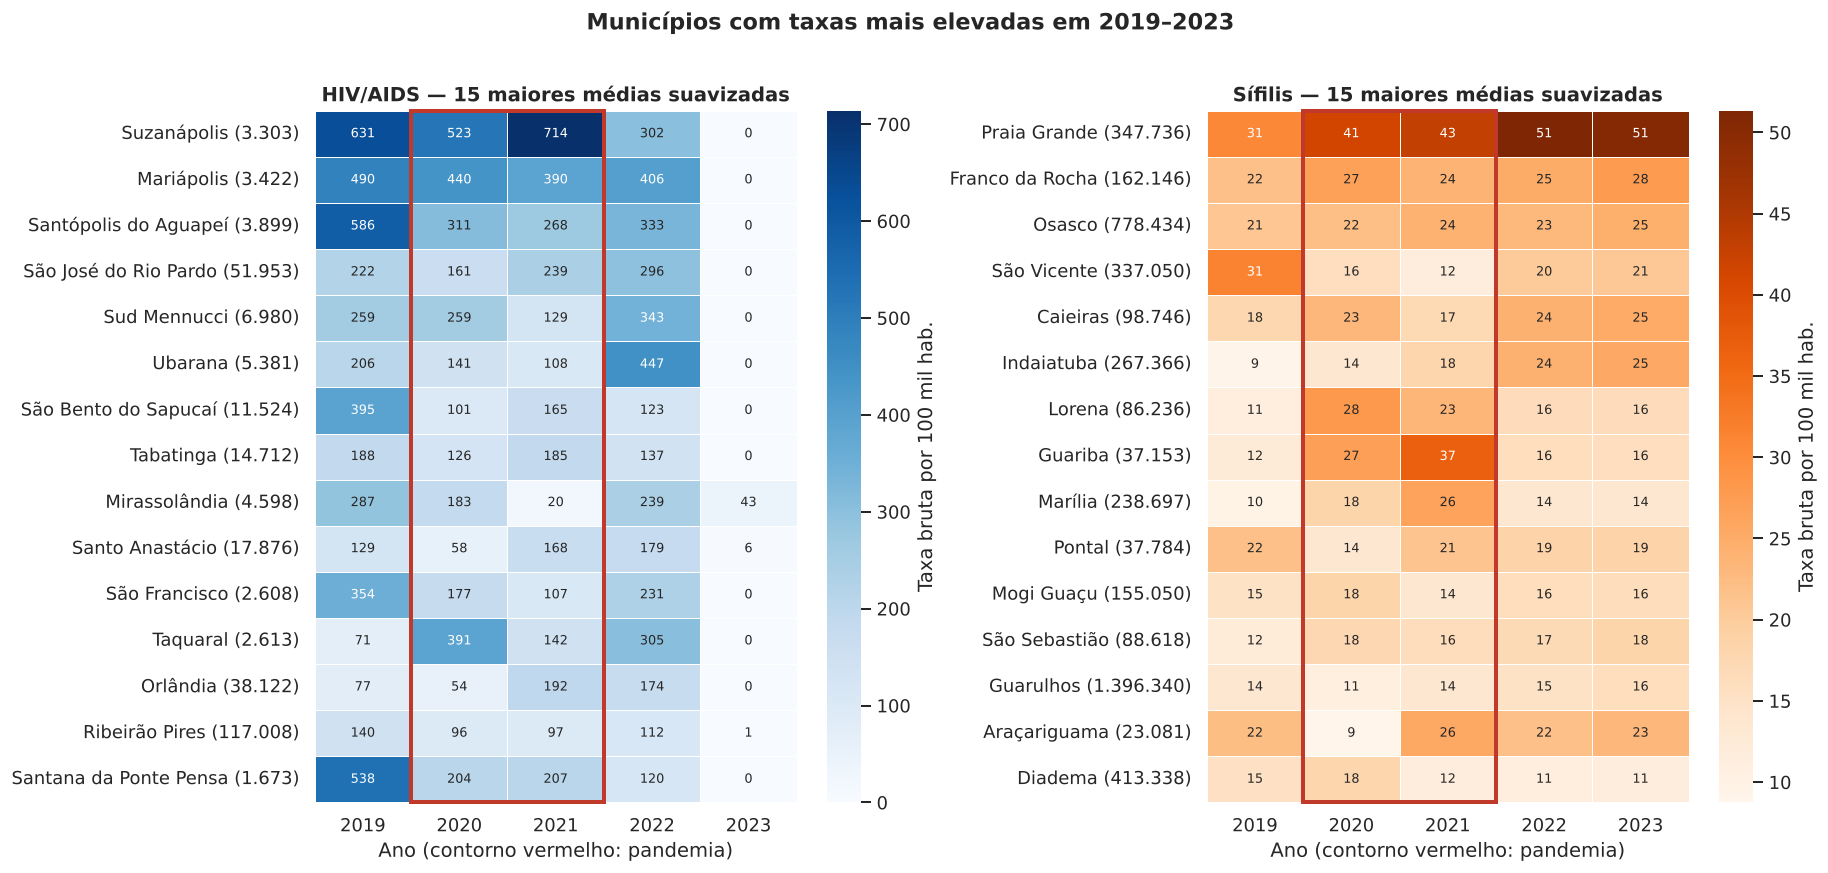

In [24]:
N_DESTAQUE = 15
pop_2022 = esp[esp.ano == 2022].set_index("CD_MUN")["populacao"]
destaques = {}
fig, eixos = plt.subplots(1, 2, figsize=(16, 7.5))
for ax, v in zip(eixos, DESFECHOS):
    media_eb = esp.groupby(["CD_MUN", "municipio"])[f"{v}_eb"].mean().sort_values(ascending=False)
    top = media_eb.head(N_DESTAQUE).reset_index()
    destaques[v] = top.assign(populacao_2022=top.CD_MUN.map(pop_2022).round())
    mapa_calor = (esp[esp.CD_MUN.isin(top.CD_MUN)]
                  .pivot(index="CD_MUN", columns="ano", values=v).loc[top.CD_MUN])
    mapa_calor.index = [f"{m} ({pop_2022[c]:,.0f})".replace(",", ".") for c, m in zip(top.CD_MUN, top.municipio)]
    sns.heatmap(mapa_calor, annot=True, fmt=".0f", cmap=CMAP[v], cbar_kws={"label": f"Taxa bruta {UNIDADE_TAXA}"},
                linewidths=0.4, linecolor="white", ax=ax, annot_kws={"fontsize": 8})
    ax.add_patch(mpatches.Rectangle((1, 0), 2, N_DESTAQUE, fill=False, edgecolor=COR_PANDEMIA, lw=2.5, clip_on=False))
    ax.set(title=f"{rotulos[v]} — {N_DESTAQUE} maiores médias suavizadas", xlabel="Ano (contorno vermelho: pandemia)", ylabel="")
fig.suptitle("Municípios com taxas mais elevadas em 2019–2023", y=1.01, fontsize=14, weight="bold")
fig.tight_layout()
salvar_figura("11_municipios_destaque_heatmap.png")
tabela_destaques = pd.concat([d.assign(indicador=rotulos[v]) for v, d in destaques.items()], ignore_index=True)
salvar_tabela(tabela_destaques, "municipios_destaque_media_suavizada.csv")

## Etapa 21 — Gráfico 12: mapas anuais das taxas suavizadas

**O que será feito:** mapear, para cada ano, as taxas suavizadas de cada doença. A escala de cores é **comum aos cinco anos** de cada doença, o que permite comparar os mapas entre si; os anos da pandemia têm título em vermelho.

**Leitura:** procurar regiões que clareiam em 2020–2021 (redução das notificações) e regiões persistentemente escuras (taxas elevadas em todo o período).

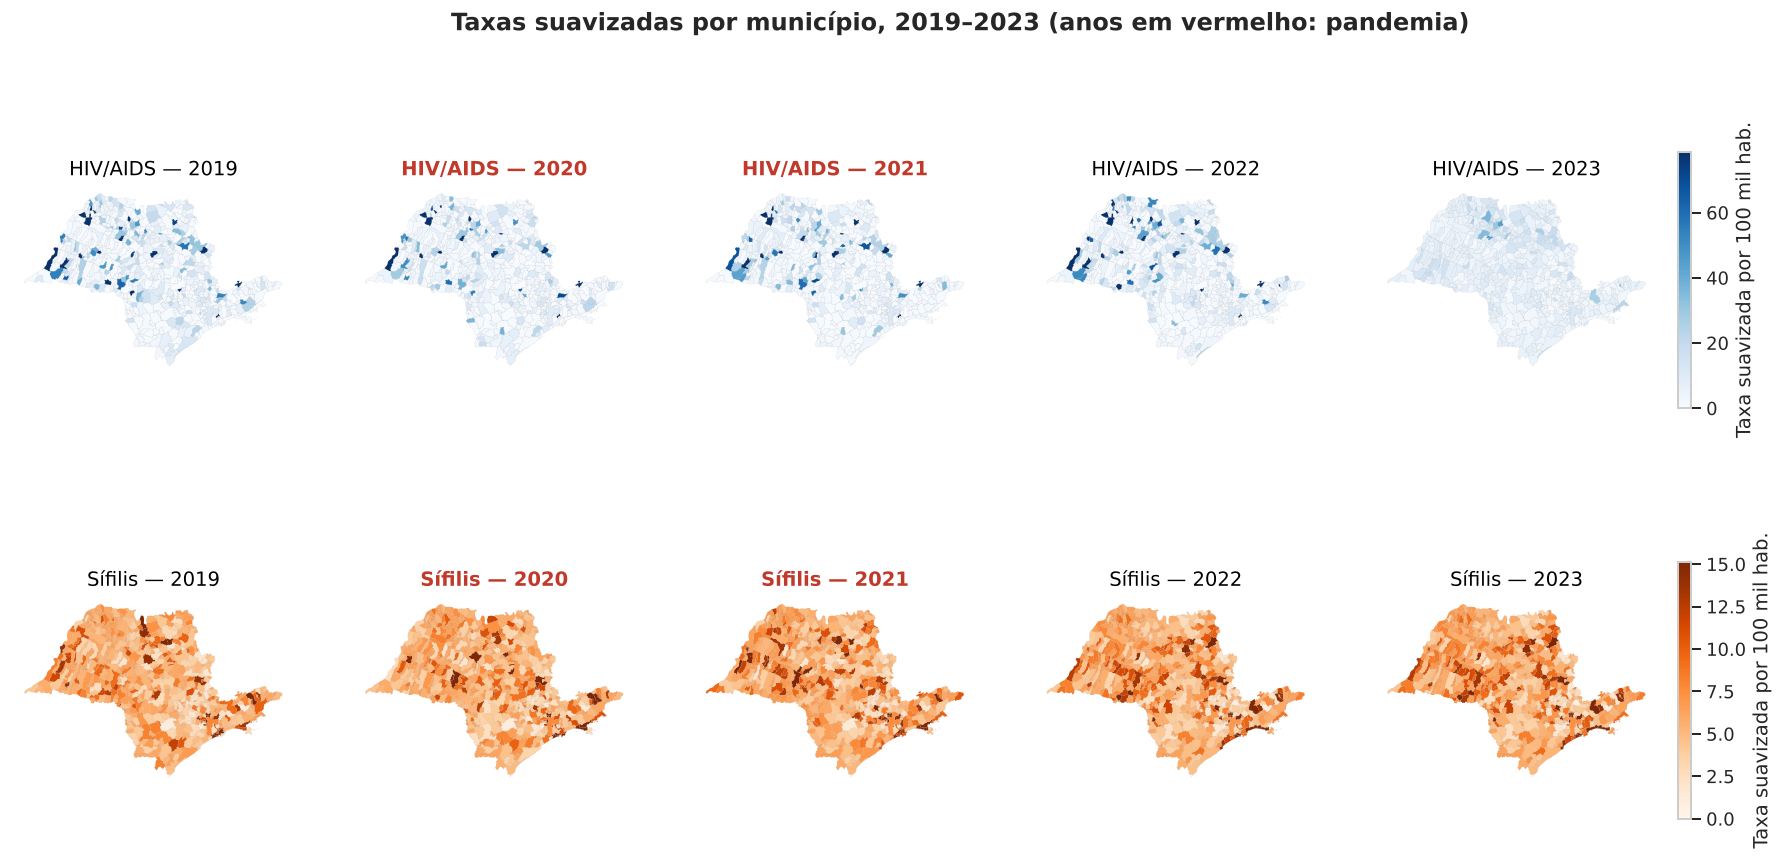

In [25]:
geo = malha.merge(esp, on="CD_MUN")
fig, eixos = plt.subplots(2, 5, figsize=(22, 8.5))
for i, v in enumerate(DESFECHOS):
    vmax = geo[f"{v}_eb"].quantile(0.98)
    for j, ano in enumerate(ANOS):
        ax = eixos[i, j]
        geo[geo.ano == ano].plot(column=f"{v}_eb", cmap=CMAP[v], vmin=0, vmax=vmax,
                                 linewidth=0.05, edgecolor="#999999", ax=ax)
        ax.set_title(f"{rotulos[v]} — {ano}", color=COR_PANDEMIA if ano in ANOS_PANDEMIA else "black",
                     weight="bold" if ano in ANOS_PANDEMIA else "normal")
        ax.set_axis_off()
    sm = plt.cm.ScalarMappable(cmap=CMAP[v], norm=plt.Normalize(0, vmax))
    fig.colorbar(sm, ax=eixos[i, :], shrink=0.75, pad=0.01, label=f"Taxa suavizada {UNIDADE_TAXA}")
fig.suptitle("Taxas suavizadas por município, 2019–2023 (anos em vermelho: pandemia)", fontsize=15, weight="bold")
salvar_figura("12_mapas_anuais_taxas_suavizadas.png")

## Etapa 22 — Gráfico 13: onde estão as taxas mais altas e onde a pandemia mais reduziu as notificações

**Painéis à esquerda:** taxa suavizada média de 2019–2023, com os 10 municípios de maior média identificados.
**Painéis à direita:** diferença entre a taxa suavizada média da pandemia (2020–2021) e a da linha de base (2019 e 2022). Vermelho = redução na pandemia; azul = aumento.

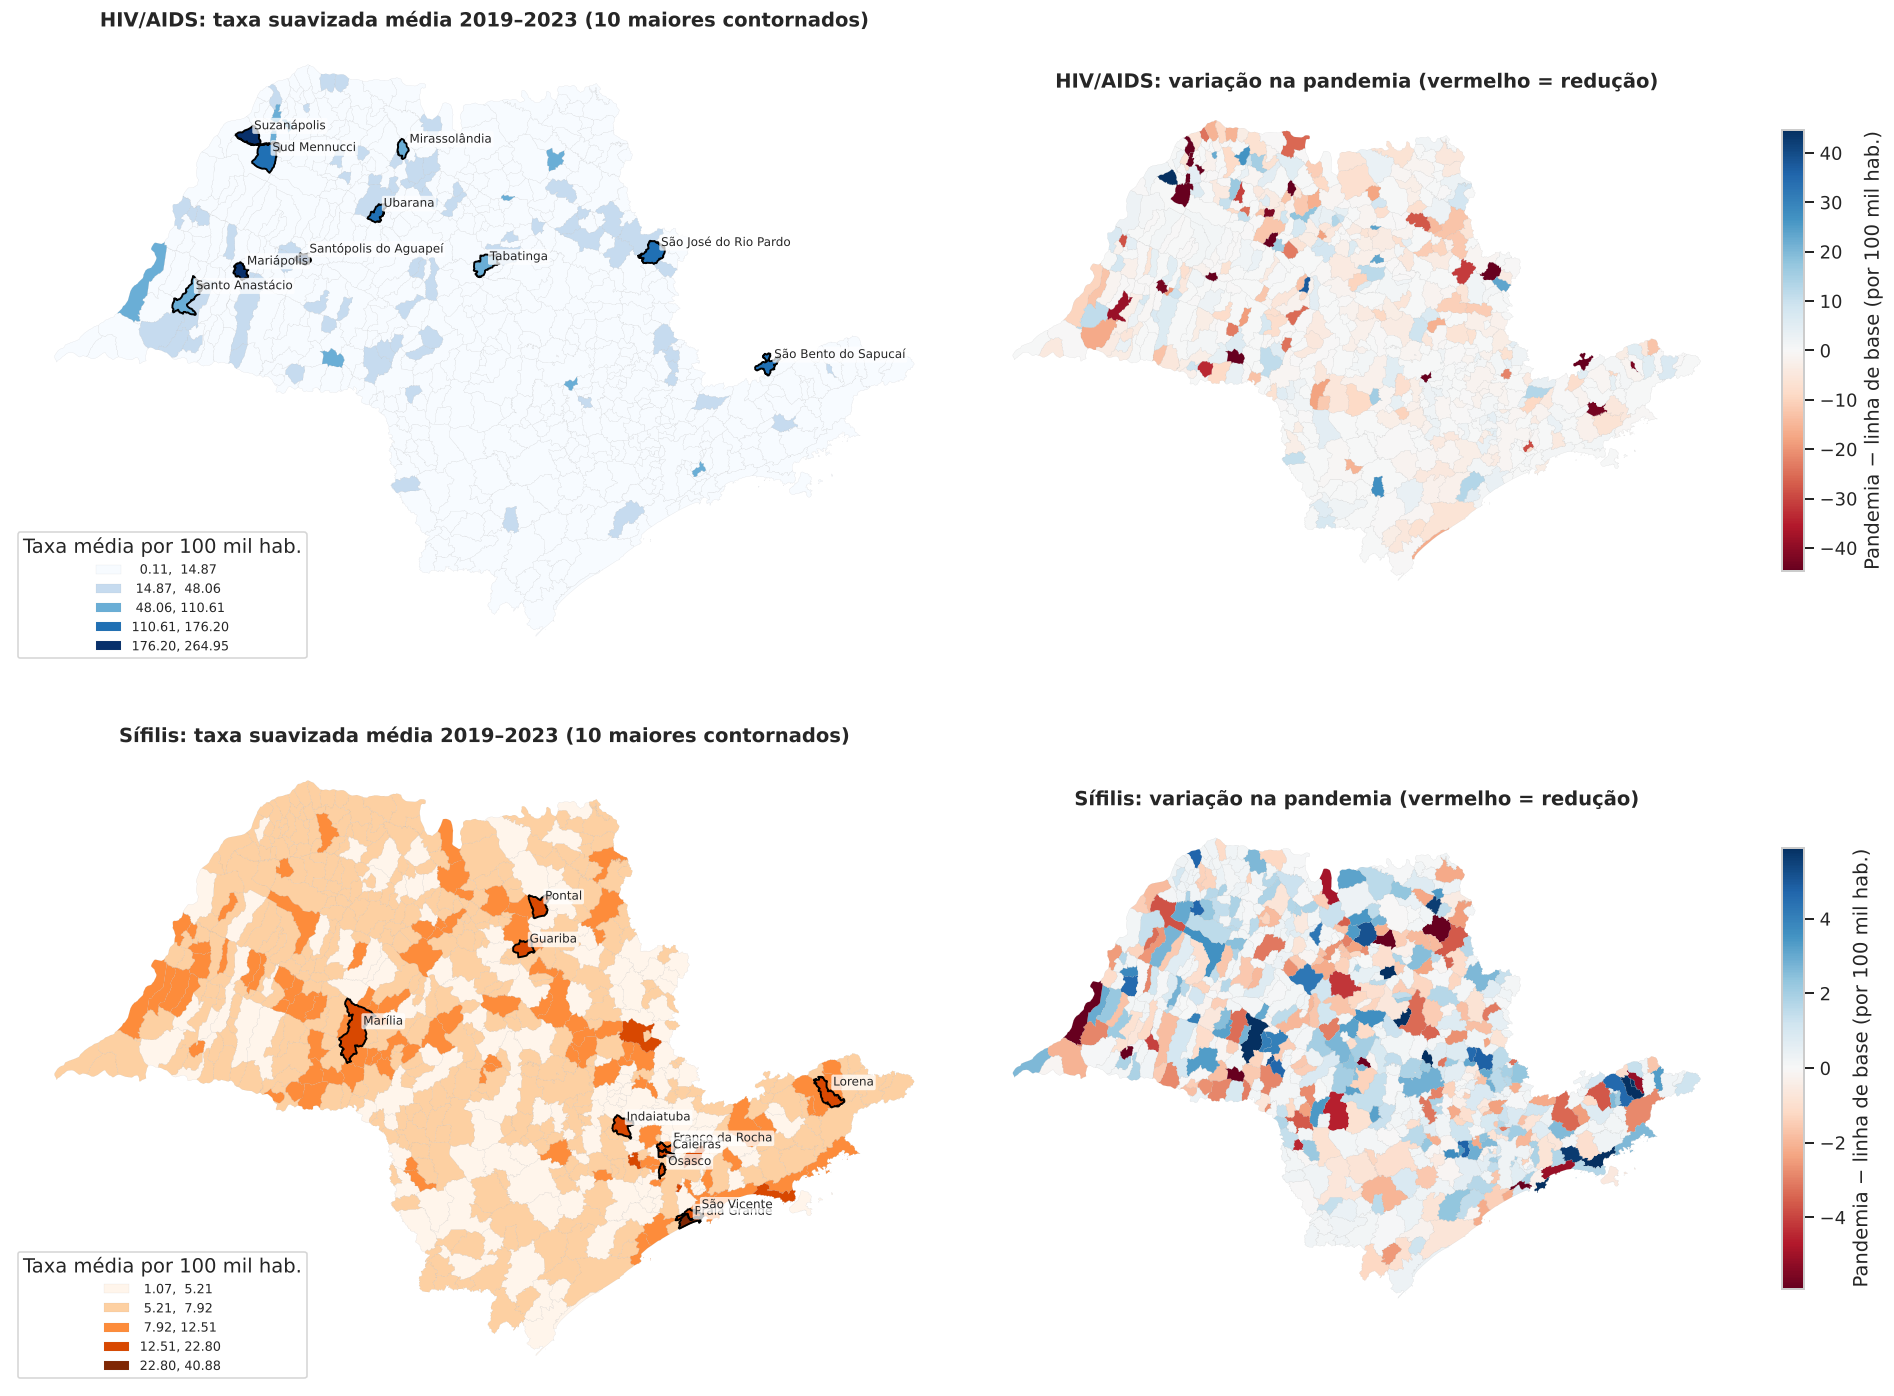

In [26]:
resumo_mun = esp.groupby("CD_MUN").agg(
    municipio=("municipio", "first"), populacao_2022=("populacao", "last"),
    **{f"{v}_media_eb": (f"{v}_eb", "mean") for v in DESFECHOS},
    **{f"{v}_media_bruta": (v, "mean") for v in DESFECHOS}).reset_index()
for v in DESFECHOS:
    base = esp[esp.ano.isin(ANOS_REFERENCIA)].groupby("CD_MUN")[f"{v}_eb"].mean()
    pand = esp[esp.ano.isin(ANOS_PANDEMIA)].groupby("CD_MUN")[f"{v}_eb"].mean()
    resumo_mun[f"{v}_variacao_pandemia"] = resumo_mun.CD_MUN.map(pand - base)
geo_mun = malha.merge(resumo_mun, on="CD_MUN")

fig, eixos = plt.subplots(2, 2, figsize=(17, 13))
for i, v in enumerate(DESFECHOS):
    ax = eixos[i, 0]
    geo_mun.plot(column=f"{v}_media_eb", cmap=CMAP[v], scheme="NaturalBreaks", k=5, legend=True,
                 legend_kwds={"title": f"Taxa média {UNIDADE_TAXA}", "loc": "lower left", "fontsize": 8},
                 linewidth=0.05, edgecolor="#999999", ax=ax)
    top10 = geo_mun.nlargest(10, f"{v}_media_eb")
    top10.boundary.plot(ax=ax, color="black", linewidth=1.2)
    for _, l in top10.iterrows():
        p = l.geometry.representative_point()
        ax.annotate(l.municipio, (p.x, p.y), xytext=(4, 4), textcoords="offset points", fontsize=7.5,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", alpha=0.75, lw=0))
    ax.set_title(f"{rotulos[v]}: taxa suavizada média 2019–2023 (10 maiores contornados)")
    ax.set_axis_off()

    ax = eixos[i, 1]
    lim = geo_mun[f"{v}_variacao_pandemia"].abs().quantile(0.98)
    geo_mun.plot(column=f"{v}_variacao_pandemia", cmap="RdBu", norm=TwoSlopeNorm(0, -lim, lim),
                 linewidth=0.05, edgecolor="#999999", ax=ax, legend=True,
                 legend_kwds={"label": f"Pandemia − linha de base ({UNIDADE_TAXA})", "shrink": 0.6})
    ax.set_title(f"{rotulos[v]}: variação na pandemia (vermelho = redução)")
    ax.set_axis_off()
fig.tight_layout()
salvar_figura("13_mapas_media_e_variacao_pandemia.png")
salvar_tabela(resumo_mun, "resumo_municipal_2019_2023.csv")

## Etapa 23 — Gráfico 14: aglomerados espaciais (Moran global e LISA)

**O que será feito:** testar se municípios vizinhos têm taxas semelhantes (**I de Moran global**) e identificar **aglomerados locais** (LISA): *Alto-Alto* (município com taxa alta cercado de vizinhos com taxa alta), *Baixo-Baixo*, e os discrepantes *Alto-Baixo* e *Baixo-Alto*. A vizinhança é definida por contiguidade do tipo rainha (municípios que compartilham fronteira ou vértice); a significância vem de 999 permutações (p < 0,05).

**Variável analisada:** taxa suavizada média de 2019–2023. Ilhabela não tem vizinhos terrestres e aparece como "ilha" na matriz de vizinhança (aviso esperado).

/usr/local/lib/python3.13/site-packages/libpysal/weights/contiguity.py:354: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 232.
  W.__init__(self, neighbors, ids=ids, **kw)
/usr/local/lib/python3.13/site-packages/esda/moran.py:1398: RuntimeWarning: invalid value encountered in divide
  self.z_sim = (self.Is - self.EI_sim) / self.seI_sim


('WARNING: ', 232, ' is an island (no neighbors)')


/usr/local/lib/python3.13/site-packages/esda/moran.py:1398: RuntimeWarning: invalid value encountered in divide
  self.z_sim = (self.Is - self.EI_sim) / self.seI_sim


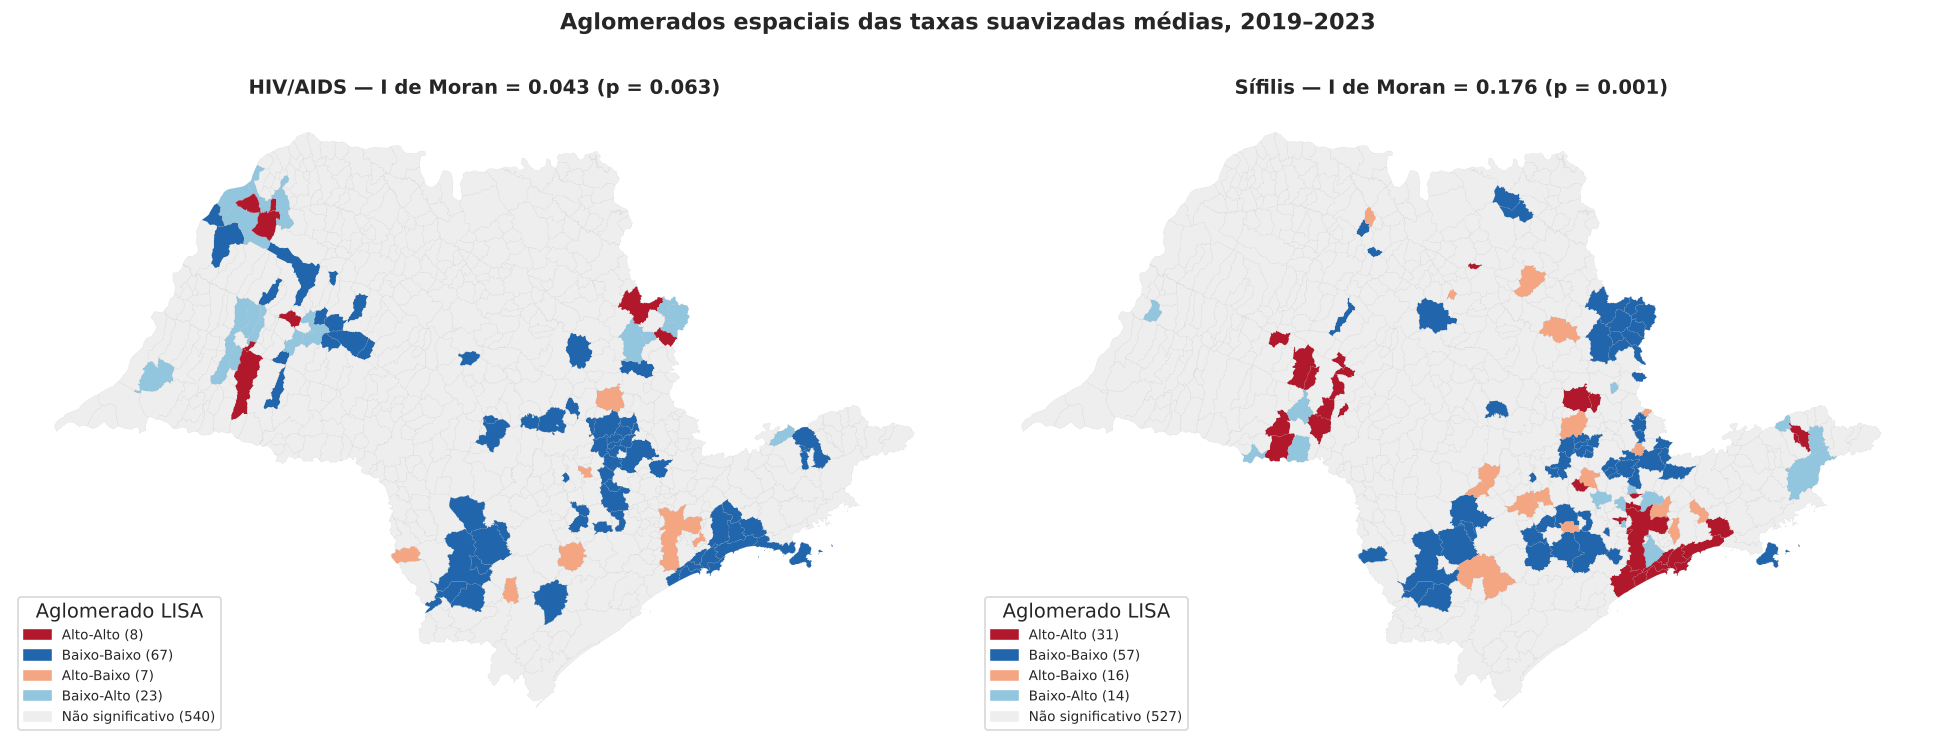

,indicador,I_Moran,p_permutacao,Alto-Alto,Baixo-Baixo,Alto-Baixo,Baixo-Alto,Não significativo
0,HIV/AIDS,0.0425,0.063,8,67,7,23,540
1,Sífilis,0.1759,0.001,31,57,16,14,527


HIV/AIDS — aglomerado Alto-Alto (8): Marinópolis, Martinópolis, Mococa, Piacatu, Pracinha, Sud Mennucci, Suzanápolis, São Sebastião da Grama
Sífilis — aglomerado Alto-Alto (31): Alvinlândia, Araras, Arco-Íris, Assis, Barueri, Bertioga, Cachoeira Paulista, Caieiras, Campos Novos Paulista, Canas, Conchal, Cubatão, Cândido Mota, Francisco Morato, Guarujá, Itanhaém, Júlio Mesquita, Mongaguá, Ocauçu, Oriente, Pompéia, Praia Grande, Salesópolis, Salto, Santos, São Paulo, São Vicente, Taboão da Serra, Taquaral, Vera Cruz, Álvaro de Carvalho


In [27]:
try:
    from libpysal.weights import Queen
    from esda.moran import Moran, Moran_Local
except ImportError:
    raise ImportError("Instale com: pip install libpysal esda")

W = Queen.from_dataframe(geo_mun, use_index=False)
W.transform = "r"
rotulos_lisa = {1: "Alto-Alto", 2: "Baixo-Alto", 3: "Baixo-Baixo", 4: "Alto-Baixo"}
cores_lisa = {"Alto-Alto": "#B2182B", "Baixo-Baixo": "#2166AC", "Alto-Baixo": "#F4A582",
              "Baixo-Alto": "#92C5DE", "Não significativo": "#EEEEEE"}

fig, eixos = plt.subplots(1, 2, figsize=(17, 7))
linhas_moran = []
for ax, v in zip(eixos, DESFECHOS):
    y = geo_mun[f"{v}_media_eb"].values
    mg = Moran(y, W, permutations=999)
    ml = Moran_Local(y, W, permutations=999, seed=42)
    classe = np.where(ml.p_sim < 0.05, pd.Series(ml.q).map(rotulos_lisa), "Não significativo")
    geo_mun[f"{v}_lisa"] = classe
    linhas_moran.append({"indicador": rotulos[v], "I_Moran": mg.I, "p_permutacao": mg.p_sim,
                         **{k: int((classe == k).sum()) for k in cores_lisa}})
    geo_mun.plot(color=geo_mun[f"{v}_lisa"].map(cores_lisa), linewidth=0.05, edgecolor="#999999", ax=ax)
    ax.legend(handles=[mpatches.Patch(color=c, label=f"{k} ({(classe == k).sum()})") for k, c in cores_lisa.items()],
              loc="lower left", fontsize=8.5, title="Aglomerado LISA")
    ax.set_title(f"{rotulos[v]} — I de Moran = {mg.I:.3f} (p = {mg.p_sim:.3f})")
    ax.set_axis_off()
fig.suptitle("Aglomerados espaciais das taxas suavizadas médias, 2019–2023", fontsize=14, weight="bold")
fig.tight_layout()
salvar_figura("14_aglomerados_LISA.png")
moran = pd.DataFrame(linhas_moran)
salvar_tabela(moran, "moran_lisa_resumo.csv")
display(moran.round(4))
for v in DESFECHOS:
    aa = geo_mun.loc[geo_mun[f"{v}_lisa"] == "Alto-Alto", "municipio"].sort_values()
    print(f"{rotulos[v]} — aglomerado Alto-Alto ({len(aa)}): {', '.join(aa)}")

## Etapa 24 — Localizar um município de interesse

**O que será feito:** a função `localizar_municipio("Nome")` mostra (i) onde o município está no estado, (ii) a série de suas taxas brutas e suavizadas comparada à taxa estadual, com a pandemia destacada, e (iii) uma tabela com os valores. A busca ignora acentos e maiúsculas. Troque o nome na última linha para pesquisar outro município.

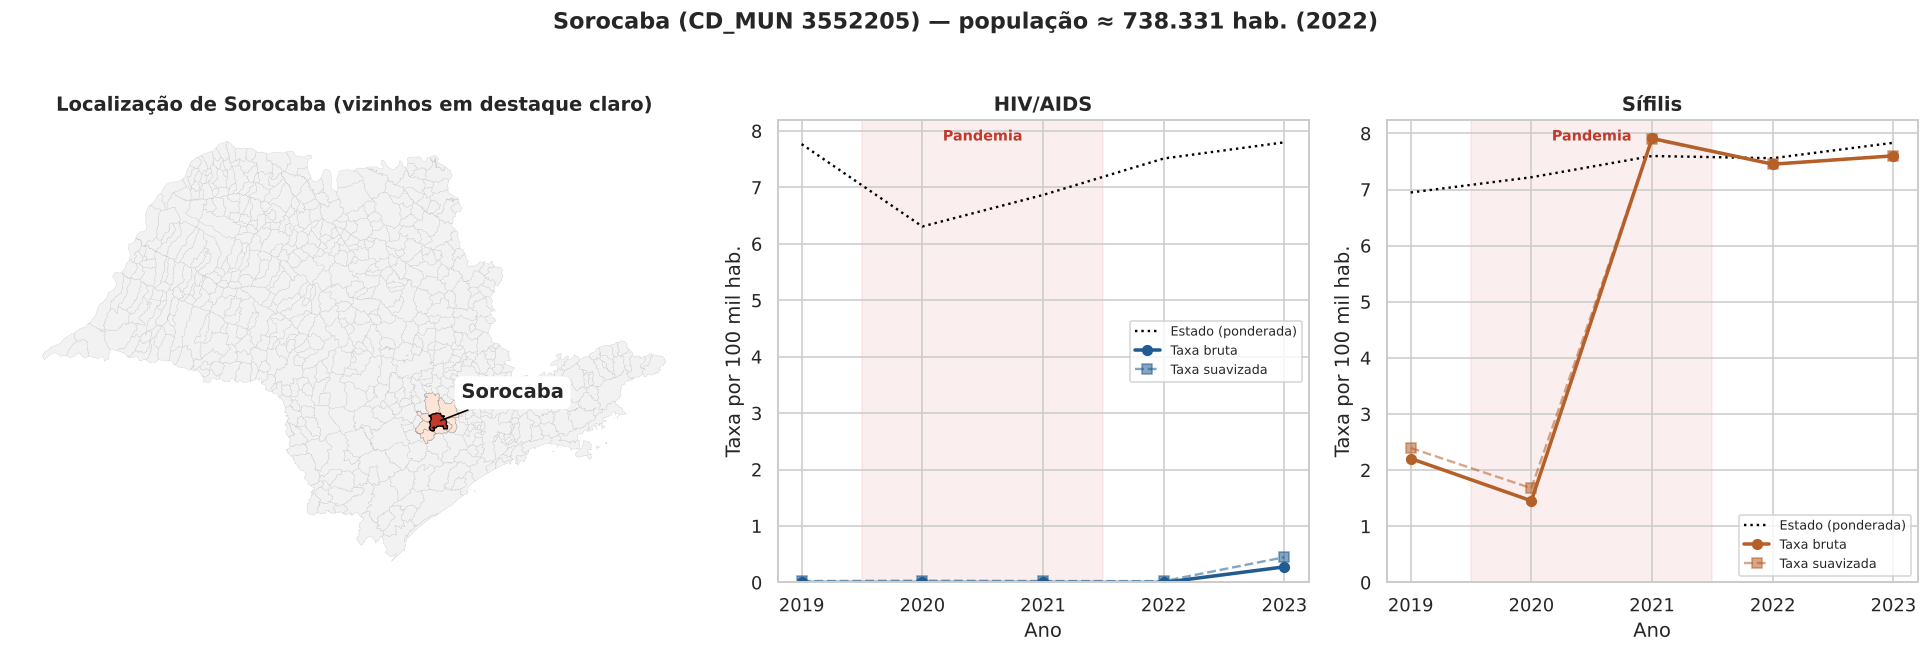

,periodo,populacao,hiv_aids,hiv_aids_eb,casos_hiv_aids,sifilis,sifilis_eb,casos_sifilis
ano,,,,,,,,
2019,Pré-pandemia,679565.30,0.00,0.02,0.0,2.21,2.40,15.0
2020,Pandemia,687546.50,0.00,0.03,0.0,1.45,1.68,10.0
2021,Pandemia,695519.70,0.00,0.03,0.0,7.91,7.90,55.0
2022,Pós-pandemia,738331.50,0.00,0.02,0.0,7.45,7.45,55.0
2023,Pós-pandemia,723881.52,0.28,0.45,2.0,7.60,7.61,55.0


HIV/AIDS: aglomerado LISA = Não significativo; posição no ranking da média suavizada = 645º de 645
Sífilis: aglomerado LISA = Baixo-Baixo; posição no ranking da média suavizada = 474º de 645


In [28]:
def localizar_municipio(nome, salvar=True):
    alvo = normalizar(nome)
    achados = resumo_mun[resumo_mun.municipio.map(normalizar) == alvo]
    if achados.empty:
        sugestoes = resumo_mun[resumo_mun.municipio.map(normalizar).str.contains(alvo[:4])].municipio.tolist()
        print(f"Município '{nome}' não encontrado. Sugestões: {sugestoes[:10]}")
        return
    cod = achados.CD_MUN.iloc[0]
    nome_oficial = achados.municipio.iloc[0]
    serie = esp[esp.CD_MUN == cod].sort_values("ano")

    fig = plt.figure(figsize=(17, 5.5))
    grade = fig.add_gridspec(1, 3, width_ratios=[1.3, 1, 1])
    ax = fig.add_subplot(grade[0])
    malha.plot(color="#F2F2F2", edgecolor="#BBBBBB", linewidth=0.15, ax=ax)
    alvo_geo = malha[malha.CD_MUN == cod]
    vizinhos = malha[malha.touches(alvo_geo.geometry.iloc[0])]
    vizinhos.plot(color="#FCE4D6", edgecolor="#999999", linewidth=0.3, ax=ax)
    alvo_geo.plot(color=COR_PANDEMIA, edgecolor="black", linewidth=0.8, ax=ax)
    p = alvo_geo.geometry.iloc[0].representative_point()
    ax.annotate(nome_oficial, (p.x, p.y), xytext=(15, 15), textcoords="offset points", weight="bold",
                arrowprops=dict(arrowstyle="-", color="black"), bbox=dict(boxstyle="round", fc="white"))
    ax.set_title(f"Localização de {nome_oficial} (vizinhos em destaque claro)")
    ax.set_axis_off()

    for k, v in enumerate(DESFECHOS):
        ax = fig.add_subplot(grade[k + 1])
        sombrear_pandemia(ax)
        est = taxa_estado[taxa_estado.indicador == rotulos[v]]
        ax.plot(est.ano, est.taxa, ":", color="black", lw=1.5, label="Estado (ponderada)")
        ax.plot(serie.ano, serie[v], "o-", color=cores[v], lw=2.2, label="Taxa bruta")
        ax.plot(serie.ano, serie[f"{v}_eb"], "s--", color=cores[v], alpha=0.55, label="Taxa suavizada")
        ax.set(title=rotulos[v], xlabel="Ano", ylabel=f"Taxa {UNIDADE_TAXA}", xticks=ANOS)
        ax.set_ylim(bottom=0)
        ax.legend(fontsize=8)
    pop = serie.loc[serie.ano == 2022, "populacao"].iloc[0]
    fig.suptitle(f"{nome_oficial} (CD_MUN {cod}) — população ≈ {pop:,.0f} hab. (2022)".replace(",", "."),
                 fontsize=14, weight="bold", y=1.03)
    fig.tight_layout()
    if salvar:
        salvar_figura(f"15_municipio_{normalizar(nome_oficial).replace(' ', '_')}.png")
    else:
        plt.show()
    tabela = serie.set_index("ano")[["periodo", "populacao", "hiv_aids", "hiv_aids_eb", "casos_hiv_aids",
                                     "sifilis", "sifilis_eb", "casos_sifilis"]]
    display(tabela.round(2))
    for v in DESFECHOS:
        print(f"{rotulos[v]}: aglomerado LISA = {geo_mun.loc[geo_mun.CD_MUN == cod, f'{v}_lisa'].iloc[0]}; "
              f"posição no ranking da média suavizada = "
              f"{int(resumo_mun[f'{v}_media_eb'].rank(ascending=False)[achados.index[0]])}º de {len(resumo_mun)}")


localizar_municipio("Sorocaba")

## Etapa 25 — Mapa interativo com busca por município

**O que será feito:** gerar um mapa interativo (`folium`) com camadas selecionáveis — taxa média suavizada de HIV/AIDS e de sífilis, variação na pandemia e os 10 municípios de maior taxa de cada doença. Ao passar o mouse sobre um município, aparecem a população e as taxas de cada ano; a lupa no canto superior esquerdo permite **buscar um município pelo nome**.

**Saída:** `resultados/mapa_interativo_SP.html`, que abre em qualquer navegador sem o Python e pode ser publicado no GitHub Pages do repositório ou incorporado ao app Shiny.

In [29]:
import folium
from folium.plugins import Search
import branca.colormap as bcm

mapa_geo = geo_mun.copy()
mapa_geo["geometry"] = mapa_geo.geometry.simplify(0.006, preserve_topology=True).set_precision(0.0001)   # arquivo mais leve
largo = {v: esp.pivot(index="CD_MUN", columns="ano", values=v) for v in DESFECHOS}

def fmt(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")

mapa_geo["pop_txt"] = mapa_geo.populacao_2022.map(lambda x: f"{x:,.0f}".replace(",", "."))
for v in DESFECHOS:
    mapa_geo[f"{v}_serie"] = mapa_geo.CD_MUN.map(
        lambda c: " | ".join(f"{a}: {fmt(largo[v].loc[c, a])}" for a in ANOS))
    mapa_geo[f"{v}_media_txt"] = mapa_geo[f"{v}_media_eb"].map(fmt)
    mapa_geo[f"{v}_var_txt"] = mapa_geo[f"{v}_variacao_pandemia"].map(lambda x: f"{x:+.1f}".replace(".", ","))

campos = ["municipio", "pop_txt", "hiv_aids_media_txt", "hiv_aids_serie", "hiv_aids_var_txt",
          "sifilis_media_txt", "sifilis_serie", "sifilis_var_txt", "hiv_aids_lisa", "sifilis_lisa"]
apelidos = ["Município", "População (2022)", f"HIV/AIDS – média suavizada {UNIDADE_TAXA}", "HIV/AIDS – taxa bruta por ano",
            "HIV/AIDS – variação na pandemia", f"Sífilis – média suavizada {UNIDADE_TAXA}", "Sífilis – taxa bruta por ano",
            "Sífilis – variação na pandemia", "Aglomerado LISA (HIV/AIDS)", "Aglomerado LISA (sífilis)"]
dados_json = mapa_geo[["CD_MUN", "geometry"] + campos + [f"{v}_media_eb" for v in DESFECHOS]
                      + [f"{v}_variacao_pandemia" for v in DESFECHOS]].to_json()

# Mapas de fundo que aceitam abertura do HTML direto do computador (o servidor do OpenStreetMap bloqueia esse uso)
m = folium.Map(location=[-22.3, -48.6], zoom_start=7, tiles=None, control_scale=True)
folium.TileLayer("https://{s}.basemaps.cartocdn.com/light_all/{z}/{x}/{y}{r}.png", subdomains="abcd",
                 attr="&copy; OpenStreetMap contributors &copy; CARTO", name="Fundo claro (CARTO)", max_zoom=19).add_to(m)
folium.TileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
                 attr="Tiles &copy; Esri", name="Fundo cinza (Esri)", max_zoom=16).add_to(m)
itens_legenda = []
paletas = {"hiv_aids": ["#EFF3FF", "#BDD7E7", "#6BAED6", "#3182BD", "#08519C"],
           "sifilis": ["#FEEDDE", "#FDBE85", "#FD8D3C", "#E6550D", "#A63603"]}

def camada(titulo, coluna, escala, mostrar):
    folium.GeoJson(
        dados_json, name=titulo, show=mostrar,
        style_function=lambda f, c=coluna, e=escala: {
            "fillColor": e(f["properties"][c]), "color": "#777777", "weight": 0.3, "fillOpacity": 0.8},
        highlight_function=lambda f: {"weight": 2.5, "color": "black"},
        tooltip=folium.GeoJsonTooltip(fields=campos, aliases=apelidos, sticky=True),
    ).add_to(m)

for k, v in enumerate(DESFECHOS):
    vmax = mapa_geo[f"{v}_media_eb"].quantile(0.98)
    escala = bcm.StepColormap(paletas[v], vmin=0, vmax=vmax,
                              index=list(np.linspace(0, vmax, 6)),
                              caption=f"{rotulos[v]} – taxa suavizada média 2019–2023 ({UNIDADE_TAXA})")
    camada(f"{rotulos[v]} – taxa média 2019–2023", f"{v}_media_eb", escala, mostrar=(k == 0))
    cortes = escala.index
    itens_legenda.append(f"<b>{rotulos[v]}</b> – taxa média 2019–2023 ({UNIDADE_TAXA})<br>" + "".join(
        f"<span style='background:{cor};width:14px;height:10px;display:inline-block;margin-right:4px;border:1px solid #999'></span>"
        f"{fmt(cortes[i], 0)}–{fmt(cortes[i + 1], 0)}{'+' if i == len(paletas[v]) - 1 else ''}<br>"
        for i, cor in enumerate(paletas[v])))
    lim = mapa_geo[f"{v}_variacao_pandemia"].abs().quantile(0.98)
    escala_var = bcm.LinearColormap(["#B2182B", "#F7F7F7", "#2166AC"], vmin=-lim, vmax=lim,
                                    caption=f"{rotulos[v]} – variação na pandemia (vermelho = redução)")
    camada(f"{rotulos[v]} – variação na pandemia", f"{v}_variacao_pandemia", escala_var, mostrar=False)

    grupo = folium.FeatureGroup(name=f"{rotulos[v]} – 10 maiores taxas", show=(k == 0))
    for _, l in geo_mun.nlargest(10, f"{v}_media_eb").iterrows():
        p = l.geometry.representative_point()
        folium.CircleMarker([p.y, p.x], radius=7, color="black", weight=1.5, fill=True,
                            fill_color=cores[v], fill_opacity=0.9,
                            tooltip=f"<b>{l.municipio}</b><br>{rotulos[v]}: {fmt(l[f'{v}_media_eb'])} {UNIDADE_TAXA}").add_to(grupo)
    grupo.add_to(m)

busca = folium.GeoJson(dados_json, name="Busca", show=True,
                       style_function=lambda f: {"fillOpacity": 0, "weight": 0, "color": "transparent"},
                       control=False).add_to(m)
Search(layer=busca, search_label="municipio", placeholder="Buscar município...", collapsed=False,
       search_zoom=10, geom_type="Polygon").add_to(m)
itens_legenda.append("<b>Variação na pandemia</b><br>"
    "<span style='background:linear-gradient(to right,#B2182B,#F7F7F7,#2166AC);width:120px;height:10px;"
    "display:inline-block;border:1px solid #999'></span><br>vermelho = redução · azul = aumento")
m.get_root().html.add_child(folium.Element(
    "<div style='position:fixed;bottom:30px;left:10px;z-index:9999;background:white;padding:8px 10px;"
    "border-radius:6px;box-shadow:0 1px 4px rgba(0,0,0,.3);font:12px sans-serif;line-height:1.35'>"
    + "<hr style='margin:5px 0'>".join(itens_legenda) + "</div>"))
folium.LayerControl(collapsed=False).add_to(m)

ARQ_MAPA = PASTA_RESULTADOS / "mapa_interativo_SP.html"
m.save(ARQ_MAPA)
print(f"Mapa salvo em: {ARQ_MAPA} ({ARQ_MAPA.stat().st_size / 1e6:.1f} MB)")
m

Mapa salvo em: /home/claude/nb/resultados/mapa_interativo_SP.html (4.5 MB)


## Etapa 26 — Arquivos gerados pela Parte II e síntese

**Ressalvas desta parte:** (1) a população é reconstruída a partir da densidade e da área da malha, e é aproximada; (2) a correção da capital/São Miguel Arcanjo deve ser confirmada na fonte; (3) com um único ano pré-pandêmico, as razões O/E descrevem a variação relativa à linha de base, sem separar efeito da pandemia de tendência prévia; (4) as taxas de municípios com unidades prisionais refletem também a população carcerária; (5) **os alertas da verificação de integridade** (cópia de 2022 em 2023 e casos de HIV/AIDS aparentemente atribuídos a municípios errados em 2019–2022) limitam as conclusões, em especial para HIV/AIDS, até que os dados sejam reextraídos do DATASUS/TabNet.

In [30]:
for v in DESFECHOS:
    l = oe[(oe.indicador == rotulos[v]) & (oe.estrato == "Estado de SP")].iloc[0]
    print(f"{rotulos[v]}: O/E na pandemia = {l.OE:.2f} (IC 95% {l.ic_inf:.2f}–{l.ic_sup:.2f}); "
          f"{int(l.observados)} casos observados vs {l.esperados:.0f} esperados.")
print()
novos = sorted(x.relative_to(PASTA_PROJETO).as_posix() for x in PASTA_RESULTADOS.rglob("*") if x.is_file())
print(f"Total de arquivos em resultados/: {len(novos)}")
for nome in novos:
    print("•", nome)

HIV/AIDS: O/E na pandemia = 0.86 (IC 95% 0.84–0.88); 6161 casos observados vs 7144 esperados.
Sífilis: O/E na pandemia = 1.02 (IC 95% 1.00–1.05); 6928 casos observados vs 6783 esperados.

Total de arquivos em resultados/: 28
• resultados/base_municipio_ano.csv
• resultados/correlacoes_spearman_por_ano.csv
• resultados/estatisticas_descritivas_anuais.csv
• resultados/graficos/01_evolucao_anual.png
• resultados/graficos/02_distribuicao_boxplots.png
• resultados/graficos/03_percentual_zeros.png
• resultados/graficos/04_evolucao_correlacoes.png
• resultados/graficos/05_matriz_correlacao_2022.png
• resultados/graficos/06_dispersoes_indicadores_2022.png
• resultados/graficos/07_top_10_municipios_2022.png
• resultados/graficos/08_coeficientes_modelos.png
• resultados/graficos/09_taxa_estadual_pandemia.png
• resultados/graficos/10_observado_esperado_pandemia.png
• resultados/graficos/11_municipios_destaque_heatmap.png
• resultados/graficos/12_mapas_anuais_taxas_suavizadas.png
• resultados/graf